# M14.3 — Mondrian v2: score normalizado por σ (M14.1)

**Pre-registro:** `docs/experiments/M14_3_mondrian_v2.md` (11-11-2026), con su enmienda 1 (gate de val). Este notebook lo aplica literalmente.

- **Modelo:** M14.1 (`M14_1_4a_G3T_hetero_s123_final.pt`), μ y σ estandarizadas, sobre cal, test y val de G3T.
  Inferencia: `configs/prediction/predict_m14_1_4aG3T_hetero_s123_on_G3T_{cal,test,val}.json`.
- **v1:** el Mondrian de la enmienda 6 de M13.13 sin cambios, aplicado a μ y calibrado solo en cal: se ejecutan las celdas 6 (ajuste) y 8 (aplicación y evaluación) del notebook cerrado de M13.7, igual que hizo `notebooks/m13/M13_13_mondrian_G3T.ipynb`.
- **v2:** los mismos bins y la misma asignación de filas que v1. Los bins de v1 se calculan una vez y v2 los reutiliza. El residuo r = y − μ se sustituye por r/σ antes del mismo cálculo de cuantiles (`BinGrouper` + `ConformalIntervalCalibrator`, con los mismos parámetros que el calibrador de v1). Después los offsets se reescalan con σ por fila: [μ + q_lo·σ, μ + q_hi·σ], con q_lo = −q y q_hi = q en modo simétrico. `src/conformal` no se modifica.
- **Decisión en val** (criterios 1–3). Test solo en el gate de RMSE pre-registrado y en la sección final "Confirmación (test)", sin decisión.

| Origen | Celda | Qué se reutiliza |
|---|---|---|
| M13.7 | 6 | Ajuste Mondrian solo con cal: selección congelada de M11 en val, hiperparámetros y `fit_selected_calibrators` |
| M13.7 | 8 | Aplicación (`apply_mondrian`) y evaluación (`evaluate_mondrian`) en un split |
| M13.7 | 11 | `read_hdf5_dataset_preserve_order` |
| M13_13_mondrian_G3T | 13 | `clopper_pearson`, `cal_ranks`, `poisson_binomial_sf` (bandas Beta-Binomial de la enmienda 6) |

## 1. Parámetros y CONFIG

In [1]:
TAG = "M14_1_4a_G3T_hetero_s123"
CHECKPOINT_REL = f"M13_3/{TAG}_final.pt"          # relative to <data_root>/models/checkpoints/
EXPECTED_CHECKPOINT_NAME = f"{TAG}_final.pt"
G3T_MARK = "m13_13_g3t"
HELDOUT_MEMMAP = "fp16_memmap_heldout"             # cal/test X of G3T
VAL_MEMMAP = "fp16_memmap"                         # val X of G3T

# Inputs (relative to <data_root>/results/): M14.1 inference on G3T, one directory per split.
PRED_CAL_REL = f"M13_3/{TAG}/preds_cal_G3T/cal_predictions_embeddings.npz"
PRED_TEST_REL = f"M13_3/{TAG}/preds_test_G3T/test_predictions_embeddings.npz"
PRED_VAL_REL = f"M13_3/{TAG}/preds_val_G3T/val_predictions_embeddings.npz"
TRAIN_VAL_REL = f"M13_3/{TAG}/val_predictions_embeddings.npz"   # trainer npz: only for the val gate

TRAIN_CFG_REL = "configs/experiments/m14/train_m14_1_4aG3T_hetero_s123.json"  # dataset block: split, scaler
TRAIN_RUN_INFO_REL = f"M13_3/{TAG}/run_info.json"   # trainer record: data.memmap_dir = the X it actually read
G3_CFG_REL = "configs/experiments/m13/train_m13_4a_G3aug_s123.json"           # G3 HDF5: y and SNR, as in M14.1
SNR_KEY = "target_network_snr"

# Gates (doc + enmienda 1).
GATE_STRICT_TOL = 1e-5            # trainer read fp16 X: max |dmu| and |dsigma| (standardized)
GATE_FP16_TOL = dict(max_abs_dmu=1e-2, max_abs_dlogsigma=1e-2, max_abs_drmse_pct=0.1)   # trainer read float32 X
RMSE_REL_TOL = 0.02               # cal and test RMSE of mu within +-2 % of val
Y_RTOL, Y_ATOL = 1e-5, 1e-6
TAU_EDGE_RTOL = 1e-6

# Bands: procedure of enmienda 6 (cell 13 of M13_13_mondrian_G3T), recomputed with n of cal and m of val.
MARGINAL_BAND_LEVEL = 0.95
MC_SEED, MC_REPLICAS = 131301, 100_000   # same seed and replicas as enmienda 6; one generator, order (v1, v2) x LABELS
MARGINAL_CI_LEVEL = 0.95                 # Clopper-Pearson, val only, no cal noise (reported)
BIN_BAND_LEVEL = 0.99
P_MIN = 0.01                             # enmienda 6 criterion: reported only, it does not decide here

# Criterion 2 (efficiency) and 3 (decision).
N_BOOT, BLOCK, SEED_BOOT = 2000, 200, 143001   # BLOCK: replicates per vectorised block (memory only)
CI_LEVEL = 0.95
EFF_MARGIN_PCT = 5.0

# Pre-registered descriptive (hypothesis of M14.1).
STDZ_BAND = (0.9, 1.1)
MEANZ_MAX = 0.1

PRIMARY_POLICY = "conservative"
M13_7_RUN = "run_20261102T164134Z"
EVAL_SUMMARY_NAME = "M13_13_G3T_evaluation_summary_20261110T124625Z.json"   # tau_edges_s of val G3T (true Mc)
REF_TAG = "M13_13_4a_G3T_s123"
AMEND6_RUN = "run_20261110T234654Z"   # executed run of M13_13_mondrian_G3T (its outputs and commit 5f29ce1);
                                      # the two earlier run_* directories hold only partial outputs

CONFIG = dict(
    versions=dict(
        v1=dict(name="v1 (score r)", color="0.45"),
        v2=dict(name="v2 (score r/σ)", color="#2a6fb0"),
        amend6=dict(name="enmienda 6 (4a-G3T)", color="#c4512b"),
    ),
    labels={"chirp_mass": "chirp mass", "total_mass": "total mass", "chi_eff": "χ_eff"},
    units={"chirp_mass": "M☉", "total_mass": "M☉", "chi_eff": "adim."},
    band_color="0.85",
    nominal_color="0.2",
    fig_names=dict(a="M14_3_val_coverage_per_bin", b="M14_3_val_width_distribution",
                   c="M14_3_val_width_by_snr_tercile", d="M14_3_val_coverage_by_snr_tercile"),
)

## 2. Imports, rutas y código reutilizado

In [2]:
from pathlib import Path
from datetime import datetime, timezone
from copy import copy
from dataclasses import replace
import sys, ast, json, pickle, hashlib
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import beta, betabinom
from IPython.display import display

root = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "src/paths.py").is_file()), None)
if root is None:
    raise RuntimeError("Abrir desde cbc_pe")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from src.paths import resolve_project_root, resolve_data_root, resolve_processed_artifact
from src.conformal.selected_calibrators import fit_selected_calibrators
from src.conformal.pipeline import apply_mondrian, evaluate_mondrian, MondrianPrediction
from src.conformal.binning import BinGrouper
from src.conformal.calibration import ConformalIntervalCalibrator
from scripts.m13.m13_1_diagnostics import tau_newtonian   # same tau30 as M14.1 and M13.13

PROJECT_ROOT = resolve_project_root()
def read_json(path):
    return json.loads(Path(path).read_text())
def require(condition, message):
    if not condition:
        raise ValueError(message)
def file_sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

LABELS = ["chirp_mass", "total_mass", "chi_eff"]
POLICIES = ["conservative", "efficient"]
# Used only by the reused M13.7 cell 8, which prints its own operational criterion (not a criterion of M14.3).
COVERAGE_TOLERANCE = 0.02
MIN_BIN_N_FOR_CRITERION = 500

train_cfg = read_json(PROJECT_ROOT / TRAIN_CFG_REL)
DATA_ROOT = resolve_data_root(config_data_root=train_cfg["data_root"])
DATASET_ID_G3T = train_cfg["dataset"]["dataset_id"]
require(DATASET_ID_G3T == f"M13_G3_band1024_w16_500k/{G3T_MARK}", "Unexpected M14.1 dataset")
SPLIT_PATH = resolve_processed_artifact(data_root=DATA_ROOT, dataset_id=DATASET_ID_G3T,
                                        file_name=train_cfg["dataset"]["split_file"])
LABEL_STATS_PATH = resolve_processed_artifact(data_root=DATA_ROOT, dataset_id=DATASET_ID_G3T,
                                              file_name=train_cfg["dataset"]["label_stats_file"])
g3_ds = read_json(PROJECT_ROOT / G3_CFG_REL)["dataset"]
DATASET_ID_G3 = g3_ds["dataset_id"]
require(G3T_MARK not in DATASET_ID_G3 and DATASET_ID_G3T == f"{DATASET_ID_G3}/{G3T_MARK}", "G3 / G3T dataset ids")
G3_H5 = resolve_processed_artifact(data_root=DATA_ROOT, dataset_id=DATASET_ID_G3, file_name=g3_ds["dataset_file"])
G3T_DIR = DATA_ROOT / "processed" / DATASET_ID_G3T
MEMMAP_DIRS = {"cal": G3T_DIR / HELDOUT_MEMMAP, "test": G3T_DIR / HELDOUT_MEMMAP, "val": G3T_DIR / VAL_MEMMAP}
CHECKPOINT = DATA_ROOT / "models/checkpoints" / CHECKPOINT_REL

RESULTS = DATA_ROOT / "results"
M13_DIR = RESULTS / "M13_3"
PRED_PATHS = {"cal": RESULTS / PRED_CAL_REL, "test": RESULTS / PRED_TEST_REL, "val": RESULTS / PRED_VAL_REL}
TRAIN_VAL_NPZ = RESULTS / TRAIN_VAL_REL
TRAIN_RUN_INFO = RESULTS / TRAIN_RUN_INFO_REL
EVAL_SUMMARY = M13_DIR / "M13_13" / EVAL_SUMMARY_NAME

M13_7_NOTEBOOK = PROJECT_ROOT / "notebooks/m13/M13_7_pipeline_provisional_4b.ipynb"
AMEND6_NOTEBOOK = PROJECT_ROOT / "notebooks/m13/M13_13_mondrian_G3T.ipynb"
M13_7_DIR = M13_DIR / "M13_4b_G3aug_s123" / "M13_7_pipeline_provisional" / M13_7_RUN
M13_7_SUMMARY = M13_7_DIR / f"M13_7_summary_{M13_7_RUN.removeprefix('run_')}.json"
M11_RESULTS = RESULTS / "M11_final_G1_500k"
M11_SELECTION = M11_RESULTS / "mondrian_m11_selected_from_val.csv"
M11_BUNDLE_MANIFEST = M11_RESULTS / "mondrian_m11_selected_calibrators_frozen_provenance.json"

# Enmienda 6 (descriptive comparison only): its cal-only bundle and the 4a-G3T predictions on val and test.
AMEND6_ROOT = M13_DIR / "M13_13/mondrian_G3T"
BUNDLE_NAME = "mondrian_m13_7_4b_calibrators_cal_only.pkl"   # fixed file name of M13.7 cell 6
AMEND6_BUNDLE = AMEND6_ROOT / AMEND6_RUN / BUNDLE_NAME
AMEND6_JSON = AMEND6_ROOT / AMEND6_RUN / f"M13_13_mondrian_G3T_{AMEND6_RUN.removeprefix('run_')}.json"
REF_NPZ = {"val": M13_DIR / REF_TAG / "val_predictions_embeddings.npz",
           "test": M13_DIR / "M13_13/preds_4a_G3T_on_G3T_test/test_predictions_embeddings.npz"}

RUN_STAMP = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
OUT_ROOT = M13_DIR / "M14_3"
RUN_DIR = OUT_ROOT / f"run_{RUN_STAMP}"     # bundle of M13.7 cell 6 and CSVs of M13.7 cell 8
FIG_DIR = OUT_ROOT / "figures"
SUMMARY_PATH = OUT_ROOT / f"M14_3_summary_{RUN_STAMP}.json"
require(not RUN_DIR.exists() and not SUMMARY_PATH.exists(), "Output of this stamp already exists")

inputs_to_check = [("pred cal", PRED_PATHS["cal"]), ("pred test", PRED_PATHS["test"]), ("pred val", PRED_PATHS["val"]),
    ("trainer val npz", TRAIN_VAL_NPZ), ("trainer run_info", TRAIN_RUN_INFO),
    ("row_ids cal", MEMMAP_DIRS["cal"] / "row_ids_cal.npy"), ("row_ids test", MEMMAP_DIRS["test"] / "row_ids_test.npy"),
    ("row_ids val", MEMMAP_DIRS["val"] / "row_ids_val.npy"), ("X val (fp16 memmap)", MEMMAP_DIRS["val"] / "X_val.npy"), ("heldout manifest", MEMMAP_DIRS["cal"] / "manifest.json"),
    ("G3 HDF5 (y, SNR)", G3_H5),
    ("split", SPLIT_PATH), ("label stats (train only)", LABEL_STATS_PATH), ("checkpoint", CHECKPOINT),
    ("M13.13 evaluation summary", EVAL_SUMMARY), ("M13.7 notebook", M13_7_NOTEBOOK), ("M13.7 summary", M13_7_SUMMARY),
    ("enmienda 6 notebook", AMEND6_NOTEBOOK), ("enmienda 6 bundle", AMEND6_BUNDLE), ("enmienda 6 JSON", AMEND6_JSON),
    ("4a-G3T val npz", REF_NPZ["val"]), ("4a-G3T test npz", REF_NPZ["test"]),
    ("M11 selection (val)", M11_SELECTION), ("M11 bundle manifest", M11_BUNDLE_MANIFEST)]
path_audit = pd.DataFrame([dict(role=r, path=str(p), exists=p.is_file()) for r, p in inputs_to_check])
with pd.option_context("display.max_colwidth", None):
    display(path_audit)
require(path_audit.exists.all(), "Missing required inputs; inspect path table")
AMEND6_BUNDLE_SHA256 = file_sha256(AMEND6_BUNDLE)
require(AMEND6_BUNDLE_SHA256 == read_json(AMEND6_JSON)["mondrian"]["bundle"]["sha256"],
        "enmienda 6 bundle differs from the one recorded in its summary JSON")
print("Run stamp:", RUN_STAMP, "| enmienda 6 run:", AMEND6_RUN)

# Reuse of closed notebooks without copying them (same mechanism as M13_13_mondrian_G3T, cell 6).
NOTEBOOK_CELLS = {"M13_7": read_json(M13_7_NOTEBOOK)["cells"], "M13_13_mondrian_G3T": read_json(AMEND6_NOTEBOOK)["cells"]}
reused_sources = {}

def reuse_cell(source, cell_index, names=None):
    """Run a code cell of a closed notebook here, or only the functions in `names`."""
    cell = NOTEBOOK_CELLS[source][cell_index]
    require(cell["cell_type"] == "code", f"{source} cell {cell_index} is not code")
    text = "".join(cell["source"])
    tree = ast.parse(text)
    if names is not None:
        tree.body = [n for n in tree.body if isinstance(n, ast.FunctionDef) and n.name in names]
        require({n.name for n in tree.body} == set(names), f"{source} cell {cell_index} does not define {names}")
    reused_sources[f"{source}/cell_{cell_index}"] = dict(names=names, sha256=hashlib.sha256(text.encode()).hexdigest())
    exec(compile(tree, f"{source}_cell_{cell_index}", "exec"), globals())

def reuse_m13_7(cell_index, names=None):
    reuse_cell("M13_7", cell_index, names)

reuse_m13_7(11, ["read_hdf5_dataset_preserve_order"])
reuse_cell("M13_13_mondrian_G3T", 13, ["clopper_pearson", "cal_ranks", "poisson_binomial_sf"])
print(json.dumps(reused_sources, indent=2))

,role,path,exists
0,pred cal,/data/vserrano/cbc_pe_data/results/M13_3/M14_1_4a_G3T_hetero_s123/preds_cal_G3T/cal_predictions_embeddings.npz,True
1,pred test,/data/vserrano/cbc_pe_data/results/M13_3/M14_1_4a_G3T_hetero_s123/preds_test_G3T/test_predictions_embeddings.npz,True
2,pred val,/data/vserrano/cbc_pe_data/results/M13_3/M14_1_4a_G3T_hetero_s123/preds_val_G3T/val_predictions_embeddings.npz,True
3,trainer val npz,/data/vserrano/cbc_pe_data/results/M13_3/M14_1_4a_G3T_hetero_s123/val_predictions_embeddings.npz,True
4,trainer run_info,/data/vserrano/cbc_pe_data/results/M13_3/M14_1_4a_G3T_hetero_s123/run_info.json,True
5,row_ids cal,/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_13_g3t/fp16_memmap_heldout/row_ids_cal.npy,True
6,row_ids test,/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_13_g3t/fp16_memmap_heldout/row_ids_test.npy,True
7,row_ids val,/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_13_g3t/fp16_memmap/row_ids_val.npy,True
8,X val (fp16 memmap),/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_13_g3t/fp16_memmap/X_val.npy,True
9,heldout manifest,/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_13_g3t/fp16_memmap_heldout/manifest.json,True


Run stamp: 20261111T152944Z | enmienda 6 run: run_20261110T234654Z
{
  "M13_7/cell_11": {
    "names": [
      "read_hdf5_dataset_preserve_order"
    ],
    "sha256": "f099a982debdc92ba1beff856b10043efd228a7fd7f2ee23d2499566f4e25a0c"
  },
  "M13_13_mondrian_G3T/cell_13": {
    "names": [
      "clopper_pearson",
      "cal_ranks",
      "poisson_binomial_sf"
    ],
    "sha256": "82c1b12fee2ed3fe83e25ecc684cf10dc6cbf3e0354cdea299f3997d3b98f97b"
  }
}


## 3. Gates (si falla alguno, el notebook se para)

Carga y procedencia de los tres npz de M14.1: checkpoint, `memmap_dir` de G3T, escalador train-only y orden de etiquetas. También se comprueba `sigma_<split>` presente, finita y > 0, `idx` = pertenencia al split = `row_ids` del memmap, sin solapamiento, e `y` = `y` del HDF5 de G3 en esas filas.

In [3]:
CHECKS = []
def check(ok, name):
    require(bool(ok), "Check failed: " + name)
    CHECKS.append(name)

with np.load(LABEL_STATS_PATH) as stats:
    stats_mean, stats_std = (stats[k].astype(np.float32) for k in ("y_mean", "y_std"))
y_mean, y_std = stats_mean.astype(float), stats_std.astype(float)
with np.load(SPLIT_PATH, allow_pickle=True) as z:
    split_indices = {s: np.asarray(z[f"{s}_idx"], dtype=np.int64) for s in ("train", "val", "cal", "test")}

SPLITS, NPZ_PROVENANCE = {}, {}
for s, path in PRED_PATHS.items():
    with np.load(path, allow_pickle=True) as z:
        check(z["available_splits"].tolist() == [s], f"{s}: npz holds only split {s}")
        check(z["label_names"].tolist() == LABELS, f"{s}: label order {LABELS}")
        check(f"sigma_{s}" in z.files, f"{s}: sigma_{s} present (heteroscedastic model)")
        prov = {k: str(z[k].item()) for k in ("checkpoint_file", "split_path", "label_stats_path", "memmap_dir")}
        mc = z["model_config"].item()
        prov.update(model_class=mc["class_name"], heteroscedastic=bool(mc["model_kwargs"].get("heteroscedastic", False)),
                    input_normalization=z["input_normalization"].item())
        check(np.array_equal(z["y_mean"], stats_mean) and np.array_equal(z["y_std"], stats_std),
              f"{s}: y_mean/y_std = train-only label stats")
        SPLITS[s] = dict(idx=np.asarray(z[f"idx_{s}"], dtype=np.int64), pred=np.asarray(z[f"pred_{s}"], dtype=float),
                         sigma=np.asarray(z[f"sigma_{s}"], dtype=float), y=np.asarray(z[f"y_{s}"], dtype=float),
                         emb=np.asarray(z[f"emb_{s}"], dtype=float))
    NPZ_PROVENANCE[s] = prov
    mm = Path(prov["memmap_dir"]).parts
    check(Path(prov["checkpoint_file"]).name == EXPECTED_CHECKPOINT_NAME, f"{s}: checkpoint_file is {EXPECTED_CHECKPOINT_NAME}")
    check(prov["heteroscedastic"], f"{s}: model_kwargs.heteroscedastic = True")
    check(mm[-3:-1] == (DATASET_ID_G3, G3T_MARK) and mm[-1] == MEMMAP_DIRS[s].name,
          f"{s}: memmap_dir is {DATASET_ID_G3}/{G3T_MARK}/{MEMMAP_DIRS[s].name}")
    check(Path(prov["split_path"]).name == SPLIT_PATH.name, f"{s}: split file")
    check(Path(prov["label_stats_path"]).name == LABEL_STATS_PATH.name, f"{s}: label stats file")
    check(prov["input_normalization"] == train_cfg["input_normalization"], f"{s}: input normalization contract")
check(len({p["model_class"] for p in NPZ_PROVENANCE.values()}) == 1, "same model class in the three npz")
EMB_DIM = SPLITS["cal"]["emb"].shape[1]

heldout_manifest = read_json(MEMMAP_DIRS["cal"] / "manifest.json")
check(Path(heldout_manifest["source_hdf5"]["path"]).name == G3_H5.name, "heldout manifest: source HDF5 is the G3 HDF5")
for s, d in SPLITS.items():
    n = len(split_indices[s])
    check(d["idx"].shape == (n,) and len(np.unique(d["idx"])) == n, f"{s}: {n} unique idx")
    for name, width in (("pred", 3), ("sigma", 3), ("y", 3), ("emb", EMB_DIM)):
        check(d[name].shape == (n, width) and np.isfinite(d[name]).all(), f"{s}: {name} shape and finite")
    check(np.all(d["sigma"] > 0), f"{s}: sigma > 0 in every row")
    check(np.array_equal(np.sort(d["idx"]), np.sort(split_indices[s])), f"{s}: idx = split membership")
    row_ids = np.load(MEMMAP_DIRS[s] / f"row_ids_{s}.npy").astype(np.int64)
    check(np.array_equal(np.sort(d["idx"]), np.sort(row_ids)), f"{s}: idx = row_ids of {MEMMAP_DIRS[s].name}")
    if s in ("cal", "test"):
        check(heldout_manifest["splits"][s]["n_rows_written"] == n, f"{s}: heldout rows written")
for a, b in (("cal", "test"), ("cal", "val"), ("test", "val")):
    check(np.intersect1d(SPLITS[a]["idx"], SPLITS[b]["idx"]).size == 0, f"no overlap {a}/{b}")

# y of the three splits = y of the G3 HDF5 at those rows (G3T shares the G3 labels).
with h5py.File(G3_H5, "r") as h:
    check(h.attrs.get("experiment_id") == DATASET_ID_G3, "G3 HDF5 experiment_id")
    check(str(h.attrs.get("labels")).split(",") == LABELS, "G3 HDF5 label order")
    y_h5 = {s: read_hdf5_dataset_preserve_order(h, "y", SPLITS[s]["idx"]).astype(float) for s in SPLITS}
for s in SPLITS:
    y_phys = SPLITS[s]["y"] * y_std + y_mean
    print(f"{s}: max |y_npz - y_G3h5| (physical) =", np.abs(y_phys - y_h5[s]).max(0))
    check(np.isclose(y_phys, y_h5[s], rtol=Y_RTOL, atol=Y_ATOL).all(), f"{s}: y = y of the G3 HDF5")

# Trainer val npz (for the gate only).
with np.load(TRAIN_VAL_NPZ, allow_pickle=False) as z:
    check({"pred_val", "sigma_val", "idx_val", "y_val"} <= set(z.files), "trainer npz: pred/sigma/idx/y of val")
    if "checkpoint_file" in z.files:
        check(Path(str(z["checkpoint_file"])).name == EXPECTED_CHECKPOINT_NAME, "trainer npz: checkpoint")
    TRAIN_VAL = dict(idx=z["idx_val"].astype(np.int64), pred=z["pred_val"].astype(float),
                     sigma=z["sigma_val"].astype(float), y=z["y_val"].astype(float))
check(np.array_equal(TRAIN_VAL["idx"], SPLITS["val"]["idx"]), "val gate: same idx, same order (trainer vs inference)")
check(np.isclose(TRAIN_VAL["y"] * y_std + y_mean, SPLITS["val"]["y"] * y_std + y_mean, rtol=Y_RTOL, atol=Y_ATOL).all(),
      "val gate: same y (trainer vs inference)")
check(np.isfinite(TRAIN_VAL["sigma"]).all() and np.all(TRAIN_VAL["sigma"] > 0), "trainer npz: sigma finite and > 0")
print("Checks passed:", len(CHECKS))

cal: max |y_npz - y_G3h5| (physical) = [2.26102156e-06 7.93715662e-06 6.16398950e-08]
test: max |y_npz - y_G3h5| (physical) = [2.67509404e-06 7.89169644e-06 6.15315230e-08]
val: max |y_npz - y_G3h5| (physical) = [2.34669051e-06 7.88831312e-06 6.16673788e-08]
Checks passed: 71


### Gate de val (doc + enmienda 1)

La rama se elige por el dtype de X de val en el fichero que leyó realmente el entrenador. Solo se leen los metadatos, no el array. `scripts/m13/train_m13_3.py` no usa `training.data_loading_mode`: lee train y val de `<processed>/<dataset_id>/fp16_memmap/` y registra ese directorio en `run_info.json` (`data.memmap_dir`). El HDF5 del bloque `dataset` es opcional para el entrenador (`data.hdf5_check`) y no existe para G3T.
- float16 → máx. |Δμ| y |Δσ| ≤ 1e-5.
- float32 → máx. |Δμ| ≤ 1e-2, máx. |Δ log σ| ≤ 1e-2 y |ΔRMSE| ≤ 0,1 % por etiqueta.

Las diferencias se calculan en unidades estandarizadas y por etiqueta.

In [4]:
run_info_data = read_json(TRAIN_RUN_INFO)["data"]
TRAINER_VAL_DIR = Path(run_info_data["memmap_dir"])
TRAINER_X_VAL = TRAINER_VAL_DIR / "X_val.npy"
check(TRAINER_VAL_DIR.resolve() == MEMMAP_DIRS["val"].resolve(), "trainer read val from the G3T fp16_memmap (run_info)")
x_val = np.load(TRAINER_X_VAL, mmap_mode="r")   # header only: dtype and shape, no data read
X_DTYPE, X_SHAPE = np.dtype(x_val.dtype), tuple(x_val.shape)
del x_val
if X_DTYPE == np.float16:
    GATE_BRANCH = "fp16 (<= 1e-5)"
elif X_DTYPE == np.float32:
    GATE_BRANCH = "float32 (tolerancias de redondeo fp16, enmienda 1)"
else:
    raise ValueError(f"Unexpected X dtype {X_DTYPE}: the gate of enmienda 1 has no branch for it")
print("Trainer val X:", TRAINER_X_VAL, "| run_info hdf5_check:", run_info_data.get("hdf5_check"))
print("X dtype:", X_DTYPE, "| shape:", X_SHAPE)
print("Rama aplicada:", GATE_BRANCH)

V = SPLITS["val"]
dmu = np.abs(V["pred"] - TRAIN_VAL["pred"])
dsigma = np.abs(V["sigma"] - TRAIN_VAL["sigma"])
dlogsigma = np.abs(np.log(V["sigma"]) - np.log(TRAIN_VAL["sigma"]))
rmse_inf = np.sqrt(np.mean(((V["pred"] - V["y"]) * y_std) ** 2, 0))
rmse_tr = np.sqrt(np.mean(((TRAIN_VAL["pred"] - TRAIN_VAL["y"]) * y_std) ** 2, 0))
drmse_pct = 100 * (rmse_inf / rmse_tr - 1)
gate_val_table = pd.DataFrame({
    "max |dmu|": dmu.max(0), "median |dmu|": np.median(dmu, 0), "P99 |dmu|": np.quantile(dmu, 0.99, axis=0),
    "max |dsigma|": dsigma.max(0),
    "max |dlogsigma|": dlogsigma.max(0), "median |dlogsigma|": np.median(dlogsigma, 0),
    "P99 |dlogsigma|": np.quantile(dlogsigma, 0.99, axis=0),
    "RMSE trainer": rmse_tr, "RMSE inference": rmse_inf, "dRMSE %": drmse_pct}, index=LABELS)
with pd.option_context("display.float_format", "{:.3g}".format):
    display(gate_val_table)
if X_DTYPE == np.float16:
    check(dmu.max() <= GATE_STRICT_TOL and dsigma.max() <= GATE_STRICT_TOL,
          f"val gate (fp16): max |dmu|, |dsigma| <= {GATE_STRICT_TOL:g}")
else:
    check(dmu.max() <= GATE_FP16_TOL["max_abs_dmu"], f"val gate (float32): max |dmu| <= {GATE_FP16_TOL['max_abs_dmu']:g}")
    check(dlogsigma.max() <= GATE_FP16_TOL["max_abs_dlogsigma"],
          f"val gate (float32): max |dlogsigma| <= {GATE_FP16_TOL['max_abs_dlogsigma']:g}")
    check(np.all(np.abs(drmse_pct) <= GATE_FP16_TOL["max_abs_drmse_pct"]),
          f"val gate (float32): |dRMSE| <= {GATE_FP16_TOL['max_abs_drmse_pct']} % per label")
GATE_VAL = dict(trainer_x_val=str(TRAINER_X_VAL), run_info=str(TRAIN_RUN_INFO), x_dtype=str(X_DTYPE), x_shape=X_SHAPE, branch=GATE_BRANCH,
                table=gate_val_table.reset_index(names="label").to_dict("records"), passed=True)
print("Gate de val superado. Las predicciones de val para la decisión son las de la inferencia fp16 (preds_val_G3T).")

Trainer val X: /data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_13_g3t/fp16_memmap/X_val.npy | run_info hdf5_check: None
X dtype: float16 | shape: (40000, 3, 16384)
Rama aplicada: fp16 (<= 1e-5)


,max |dmu|,median |dmu|,P99 |dmu|,max |dsigma|,max |dlogsigma|,median |dlogsigma|,P99 |dlogsigma|,RMSE trainer,RMSE inference,dRMSE %
chirp_mass,2.21e-06,1.19e-07,5.36e-07,1.61e-06,3.42e-06,1.48e-07,6.72e-07,5.27,5.27,-4.94e-07
total_mass,2.09e-06,1.19e-07,4.77e-07,1.1e-06,2.48e-06,1.29e-07,5.95e-07,8.8,8.8,-9.9e-08
chi_eff,2.15e-06,1.19e-07,6.85e-07,8.94e-07,1.21e-06,1.11e-07,4.75e-07,0.168,0.168,-5.17e-07


Gate de val superado. Las predicciones de val para la decisión son las de la inferencia fp16 (preds_val_G3T).


### Gate de RMSE: cal y test dentro de ±2 % de val (μ, unidades físicas)

In [5]:
rmse_rows = []
for s in ("val", "cal", "test"):
    err = (SPLITS[s]["pred"] - SPLITS[s]["y"]) * y_std
    rmse_rows.append(dict(split=s, n=len(err), **{l: float(np.sqrt(np.mean(err[:, j] ** 2))) for j, l in enumerate(LABELS)}))
rmse_table = pd.DataFrame(rmse_rows).set_index("split")
display(rmse_table)
GATE_RMSE = []
for l in LABELS:
    for s in ("cal", "test"):
        rel = rmse_table.loc[s, l] / rmse_table.loc["val", l] - 1
        print(f"{s} {l}: RMSE {rmse_table.loc[s, l]:.4g} ({100 * rel:+.2f} % vs val)")
        GATE_RMSE.append(dict(split=s, label=l, rmse=float(rmse_table.loc[s, l]), rmse_val=float(rmse_table.loc["val", l]),
                              rel_pct=float(100 * rel)))
        check(abs(rel) <= RMSE_REL_TOL, f"{s} RMSE {l} within +-{100 * RMSE_REL_TOL:.0f} % of val")
print("GATES superados:", len(CHECKS), "comprobaciones")

,n,chirp_mass,total_mass,chi_eff
split,,,,
val,40000,5.267534,8.798732,0.167779
cal,30000,5.363024,8.938043,0.169483
test,30000,5.329047,8.782387,0.164823


cal chirp_mass: RMSE 5.363 (+1.81 % vs val)
test chirp_mass: RMSE 5.329 (+1.17 % vs val)
cal total_mass: RMSE 8.938 (+1.58 % vs val)
test total_mass: RMSE 8.782 (-0.19 % vs val)
cal chi_eff: RMSE 0.1695 (+1.02 % vs val)
test chi_eff: RMSE 0.1648 (-1.76 % vs val)
GATES superados: 79 comprobaciones


## 4. Ajuste solo con cal: v1 (celda 6 de M13.7) y v2 (r/σ con los mismos bins)

La celda 6 de M13.7 se ejecuta sin cambios. Comprueba la selección y los hiperparámetros congelados de M11, ajusta los seis sistemas solo con cal (aquí, μ de M14.1) y serializa el bundle en `RUN_DIR`. El nombre del pickle y su campo `method_source` son texto fijo de esa celda y mencionan 4b-G3. Los campos `model`, `checkpoint_path` y `predictions_path` corresponden a M14.1.

**v2 (envoltura).** Para cada sistema conservative se toman los bins de cal de v1 (`bin_indices_cal`, calculados una sola vez). Sobre ellos se agrupan los scores r/σ, con r = y − μ (el mismo convenio que `fit_mondrian`), y se ajusta un `ConformalIntervalCalibrator` con el mismo nivel, el mismo modo de intervalo y el mismo mínimo por bin que el de v1. Sus offsets están en unidades de σ.

In [6]:
RUN_DIR.mkdir(parents=True, exist_ok=False)
OUTPUT_DIR = RUN_DIR                        # M13.7 cell 6 writes its bundle here
pred_cal, y_cal, emb_cal = (SPLITS["cal"][k] for k in ("pred", "y", "emb"))
PREDICTIONS_PATH = PRED_PATHS["cal"]        # field of the bundle metadata: the only predictions used for the fit
DATASET_ID = DATASET_ID_G3T                 # recorded by M13.7 cell 6 in the bundle metadata
check_helper = check                        # M13.7 cell 6 binds `check` to a DataFrame
reuse_m13_7(6)
m13_7_selection_check, check = check, check_helper

m13_7_summary = read_json(M13_7_SUMMARY)
check(m13_7_summary["mondrian"]["hyperparameters"] == HP, "Mondrian hyperparameters = M13.7")
ours_systems = selected[["final_policy", "label", "taxonomy_mode", "interval_mode", "n_bins"]].to_dict("records")
key = lambda r: (r["final_policy"], r["label"])
check(sorted(m13_7_summary["mondrian"]["systems"], key=key) ==
      sorted([{k: (int(v) if k == "n_bins" else v) for k, v in r.items()} for r in ours_systems], key=key),
      "Mondrian systems (taxonomy, interval mode, n_bins) = M13.7")

SIGMA_CAL = SPLITS["cal"]["sigma"]

def fit_v2(system):
    """Same bins as v1 (its cal bin assignment); quantiles of r/sigma with the calibrator settings of v1."""
    f, c1 = system.fitted, system.fitted.calibrator
    scores = (y_cal - pred_cal) / SIGMA_CAL          # r/sigma, r = y - mu (convention of fit_mondrian)
    grouped = BinGrouper().group_by_bin(residuals=scores, bin_indices=f.bin_indices_cal, n_bins=f.n_bins)
    c2 = ConformalIntervalCalibrator(confidence_level=c1.confidence_level, interval_mode=c1.interval_mode,
                                     min_samples_per_bin=c1.min_samples_per_bin,
                                     warn_on_extreme_quantiles=c1.warn_on_extreme_quantiles).fit(grouped)
    return replace(system, fitted=replace(f, calibrator=c2, grouped_residuals_cal=grouped))

V1_SYSTEMS = {l: calibrators[(PRIMARY_POLICY, l)] for l in LABELS}
V2_SYSTEMS = {l: fit_v2(V1_SYSTEMS[l]) for l in LABELS}
for l in LABELS:
    s1, s2 = V1_SYSTEMS[l], V2_SYSTEMS[l]
    j = s1.label_index
    check(s2.fitted.bin_indices_cal is s1.fitted.bin_indices_cal, f"{l}: v2 shares the cal bin assignment of v1")
    check(np.array_equal(s2.fitted.calibrator.bin_counts_[j], s1.fitted.calibrator.bin_counts_[j]), f"{l}: same n per bin")
    check(np.array_equal(s2.fitted.calibrator.quantile_indices_[j], s1.fitted.calibrator.quantile_indices_[j]),
          f"{l}: same order-statistic ranks in v1 and v2")
    print(f"{l:10s} {s1.taxonomy_mode}/{s1.interval_mode}/{s1.n_bins} | v2 offsets (units of sigma) per bin:\n",
          np.round(s2.fitted.calibrator.intervals_[j], 4))

,final_policy,label,label_index,selection_policy,taxonomy_mode,interval_mode,n_bins
0,conservative,chirp_mass,0,conservative_zero_under_bins_2sigma,difficulty,asymmetric,16
1,efficient,chirp_mass,0,efficient_local_validity_tolerant,difficulty,asymmetric,48
2,conservative,total_mass,1,conservative_zero_under_bins_2sigma,prediction,asymmetric,4
3,efficient,total_mass,1,efficient_local_validity_tolerant,prediction,asymmetric,4
4,conservative,chi_eff,2,conservative_zero_under_bins_2sigma,difficulty,symmetric,8
5,efficient,chi_eff,2,efficient_local_validity_tolerant,difficulty,symmetric,4


fit cal only conservative/chirp_mass: difficulty/asymmetric/16
fit cal only efficient/chirp_mass: difficulty/asymmetric/48
fit cal only conservative/total_mass: prediction/asymmetric/4
fit cal only efficient/total_mass: prediction/asymmetric/4
fit cal only conservative/chi_eff: difficulty/symmetric/8
fit cal only efficient/chi_eff: difficulty/symmetric/4
Bundle: /data/vserrano/cbc_pe_data/results/M13_3/M14_3/run_20261111T152944Z/mondrian_m13_7_4b_calibrators_cal_only.pkl 33da9d11994084c95b61d8b50441fe2343eb360d2603be01af65219cb886f4d1
chirp_mass difficulty/asymmetric/16 | v2 offsets (units of sigma) per bin:
 [[-1.4888  1.6282]
 [-1.6358  1.7041]
 [-1.6397  1.6307]
 [-1.7463  1.636 ]
 [-1.6545  1.6403]
 [-1.6927  1.6077]
 [-1.6408  1.5409]
 [-1.8018  1.5078]
 [-1.6256  1.5582]
 [-1.6577  1.5151]
 [-1.6797  1.4824]
 [-1.7962  1.5269]
 [-1.8713  1.4888]
 [-1.7552  1.435 ]
 [-1.7377  1.4882]
 [-1.7305  1.5211]]
total_mass prediction/asymmetric/4 | v2 offsets (units of sigma) per bin:
 [[-

## 5. Aplicación en val (decisión)

v1 sale de la celda 8 de M13.7, sin cambios, sobre μ de val. Esa celda escribe sus CSV con nombre fijo (`test_*.csv`) en `RUN_DIR/m13_7_cell8_val/` e imprime su propio criterio de ±2 puntos, que aquí no es criterio. v2 usa los bins de v1 en cada fila (`prediction.bin_indices`) y los offsets de v2 reescalados por σ: [μ + q_lo·σ, μ + q_hi·σ]. Se evalúa con el mismo `evaluate_mondrian`.

In [7]:
def run_m13_7_cell8(run_name, arrays, systems):
    """Run M13.7 cell 8 unchanged on one split (`arrays`: pred, y, emb, idx) with the fitted `systems`."""
    global pred_test, y_test, emb_test, idx_test, OUTPUT_DIR, calibrators
    saved = calibrators
    pred_test, y_test, emb_test, idx_test = (arrays[k] for k in ("pred", "y", "emb", "idx"))
    calibrators = systems
    OUTPUT_DIR = RUN_DIR / f"m13_7_cell8_{run_name}"
    OUTPUT_DIR.mkdir(exist_ok=False)
    try:
        reuse_m13_7(8)
    finally:
        calibrators = saved
    return test_results

def apply_v2(system2, v1_result, d):
    """v2 on one split: bins of v1 per row, offsets of v2 rescaled by sigma per row."""
    j = system2.label_index
    p1 = v1_result["prediction"]
    b = p1.bin_indices[:, 0].astype(int)
    off = system2.fitted.calibrator.intervals_[j]          # (n_bins, 2): [q_lo, q_hi]; symmetric: [-q, q]
    lower = d["pred"][:, j] + off[b, 0] * d["sigma"][:, j]
    upper = d["pred"][:, j] + off[b, 1] * d["sigma"][:, j]
    single = MondrianPrediction(lower=lower[:, None], upper=upper[:, None], bin_indices=p1.bin_indices,
                                binning_scores=p1.binning_scores)
    metrics = evaluate_mondrian(system2.fitted, single, d["y"][:, j:j+1], tolerance_sigmas=(1, 2, 3))
    return dict(system=system2, j=j, prediction=single, metrics=metrics, width_phys=(upper - lower) * y_std[j])

def per_row(result, d):
    """Covered indicator (closed interval, as CoverageEvaluator) and physical width per row."""
    p, j = result["prediction"], result["j"]
    cov = (p.lower[:, 0] <= d["y"][:, j]) & (d["y"][:, j] <= p.upper[:, 0])
    require(np.isclose(cov.mean(), result["metrics"]["global_coverage"][0], rtol=0, atol=1e-12), "coverage per row")
    return cov, result["width_phys"]

cell8_val = run_m13_7_cell8("val", SPLITS["val"], calibrators)
V1_VAL = {l: cell8_val[(PRIMARY_POLICY, l)] for l in LABELS}
V2_VAL = {l: apply_v2(V2_SYSTEMS[l], V1_VAL[l], SPLITS["val"]) for l in LABELS}
RES_VAL = {"v1": V1_VAL, "v2": V2_VAL}
ROW_VAL = {v: {l: per_row(RES_VAL[v][l], SPLITS["val"]) for l in LABELS} for v in RES_VAL}
for l in LABELS:
    check(np.array_equal(V1_VAL[l]["prediction"].bin_indices, V2_VAL[l]["prediction"].bin_indices),
          f"{l}: v1 and v2 share the val bin assignment")

,final_policy,label,taxonomy_mode,interval_mode,n_bins,n_test,coverage,coverage_gap_points,marginal_pass,n_bins_assessed,n_bins_fail,min_bin_coverage_assessed,max_bin_coverage_assessed,min_bin_n,bins_pass,mean_width_phys,median_width_phys,lower_miss_rate,upper_miss_rate
0,conservative,chi_eff,difficulty,symmetric,8,40000,0.900825,0.0825,True,8,0,0.890517,0.910363,4906,True,0.532059,0.504827,0.052675,0.046500
1,conservative,chirp_mass,difficulty,asymmetric,16,40000,0.903950,0.3950,True,16,0,0.888975,0.917993,2326,True,14.720336,14.349381,0.046350,0.049700
2,conservative,total_mass,prediction,asymmetric,4,40000,0.904125,0.4125,True,4,0,0.902334,0.907278,9727,True,27.657463,23.530149,0.046500,0.049375
3,efficient,chi_eff,difficulty,symmetric,4,40000,0.900150,0.0150,True,4,0,0.899332,0.901216,9845,True,0.531703,0.474782,0.053300,0.046550
4,efficient,chirp_mass,difficulty,asymmetric,48,40000,0.902775,0.2775,True,48,12,0.869767,0.932845,736,False,14.728882,13.800291,0.048000,0.049225
5,efficient,total_mass,prediction,asymmetric,4,40000,0.904125,0.4125,True,4,0,0.902334,0.907278,9727,True,27.657463,23.530149,0.046500,0.049375


,final_policy,label,mondrian_bin,n,coverage,assessed,within_2_points,median_width_phys
0,conservative,chi_eff,0,5013,0.900459,True,True,0.358611
1,conservative,chi_eff,1,5181,0.899054,True,True,0.428088
2,conservative,chi_eff,2,4936,0.899109,True,True,0.445721
3,conservative,chi_eff,3,4992,0.906450,True,True,0.504827
4,conservative,chi_eff,4,5127,0.903452,True,True,0.533880
5,conservative,chi_eff,5,4906,0.897065,True,True,0.575117
6,conservative,chi_eff,6,4914,0.890517,True,True,0.625580
7,conservative,chi_eff,7,4931,0.910363,True,True,0.793698
8,conservative,chirp_mass,0,2535,0.912821,True,True,1.642534
9,conservative,chirp_mass,1,2567,0.888975,True,True,2.803483


CRITERION (fixed before test): |coverage - 0.90| <= 0.02; per bin only if n >= 500
  conservative chi_eff    marginal 0.9008 [PASS]  bins 8/8 within [PASS]
  conservative chirp_mass marginal 0.9040 [PASS]  bins 16/16 within [PASS]
  conservative total_mass marginal 0.9041 [PASS]  bins 4/4 within [PASS]
  efficient    chi_eff    marginal 0.9002 [PASS]  bins 4/4 within [PASS]
  efficient    chirp_mass marginal 0.9028 [PASS]  bins 36/48 within [FAIL]
  efficient    total_mass marginal 0.9041 [PASS]  bins 4/4 within [PASS]


## 6. Criterio 1 — validez (val)

Procedimiento de la enmienda 6, recalculado con los n_b de cal y los m_b de val. El rango k_b se lee del calibrador ajustado con `cal_ranks`, reutilizada. Hay dos bandas:
- **marginal:** banda Monte Carlo del 95 %, con c_b ~ Beta(k_b, n_b − k_b + 1) y aciertos ~ Binomial(m_b, c_b);
- **por bin:** banda central del 99 % de `betabinom(m_b, k_b, n_b − k_b + 1)`.

Se usa un solo generador `default_rng(131301)`, recorrido en el orden (v1, v2) × etiquetas.

**Validez de v2:** ninguna celda (marginal ni por bin) por debajo de su banda inferior. La sobrecobertura se reporta junto a v1 y no invalida. Como los bins son compartidos, «misma celda» es el mismo bin. También se reporta el criterio de la enmienda 6 (P Poisson-binomial ≥ 0,01), solo como información.

In [8]:
def coverage_bands(results, version, rng):
    """Enmienda 6 (cell 13) bands for one version on one split; m_b from that split, k_b and n_b from cal."""
    a_bin = (1 - BIN_BAND_LEVEL) / 2
    marginal_rows, bin_rows = [], []
    for label in LABELS:
        r = results[label]
        system, m = r["system"], r["metrics"]
        k_b, n_b, qidx = cal_ranks(system)
        m_b = m["counts_per_bin"][:, 0].astype(int)
        hits_b = np.rint(np.nan_to_num(m["coverage_per_bin"][:, 0]) * m_b).astype(int)
        n = int(m_b.sum())
        require(n == len(r["width_phys"]), "bin counts do not add up")
        cov = float(m["global_coverage"][0])
        require(int(hits_b.sum()) == int(np.rint(cov * n)), "per-bin hits do not add up to the marginal")
        c = rng.beta(k_b, n_b - k_b + 1, size=(MC_REPLICAS, len(k_b)))
        sim = rng.binomial(m_b, c).sum(axis=1) / n
        mc_lo, mc_hi = np.quantile(sim, [(1 - MARGINAL_BAND_LEVEL) / 2, 1 - (1 - MARGINAL_BAND_LEVEL) / 2])
        ci_lo, ci_hi = clopper_pearson(int(hits_b.sum()), n, MARGINAL_CI_LEVEL)
        p_out_list, n_out, n_below, n_above = [], 0, 0, 0
        for b in range(len(k_b)):
            row = dict(version=version, label=label, mondrian_bin=b, n_cal=int(n_b[b]), k_rank=int(k_b[b]),
                       expected_coverage=float(k_b[b] / (n_b[b] + 1)), m=int(m_b[b]))
            if m_b[b] == 0:
                bin_rows.append(dict(row, hits=0, coverage=np.nan, band_lo=np.nan, band_hi=np.nan, p_two_sided=np.nan,
                                     below_band=False, above_band=False))
                continue
            dist = betabinom(m_b[b], k_b[b], n_b[b] - k_b[b] + 1)
            lo, hi = int(dist.ppf(a_bin)), int(dist.ppf(1 - a_bin))
            p_out_list.append(float(dist.cdf(lo - 1) + dist.sf(hi)))
            below, above = bool(hits_b[b] < lo), bool(hits_b[b] > hi)
            n_out += int(below or above)
            n_below += int(below)
            n_above += int(above)
            bin_rows.append(dict(row, hits=int(hits_b[b]), coverage=float(hits_b[b] / m_b[b]), band_lo=lo / m_b[b],
                                 band_hi=hi / m_b[b],
                                 p_two_sided=float(min(1.0, 2 * min(dist.cdf(hits_b[b]), dist.sf(hits_b[b] - 1)))),
                                 below_band=below, above_band=above))
        marginal_below, marginal_above = bool(cov < mc_lo), bool(cov > mc_hi)
        marginal_rows.append(dict(version=version, label=label, taxonomy_mode=system.taxonomy_mode,
            interval_mode=system.interval_mode, n_bins=system.n_bins, n=n, coverage=cov,
            expected_coverage_H0=float(np.sum(m_b * k_b / (n_b + 1)) / n), mc95_lo=float(mc_lo), mc95_hi=float(mc_hi),
            marginal_below=marginal_below, marginal_above=marginal_above,
            binomial_ci95_lo_split_only=ci_lo, binomial_ci95_hi_split_only=ci_hi,
            n_bins_evaluated=len(p_out_list), n_bins_below=n_below, n_bins_above=n_above,
            p_at_least_observed_outside=poisson_binomial_sf(p_out_list, n_out),
            valid=bool(not marginal_below and n_below == 0)))
    return marginal_rows, bin_rows

rng_mc = np.random.default_rng(MC_SEED)
marg, bins = [], []
for version in ("v1", "v2"):          # fixed generator order
    mr, br = coverage_bands(RES_VAL[version], version, rng_mc)
    marg += mr
    bins += br
COV_VAL = pd.DataFrame(marg)
BIN_VAL = pd.DataFrame(bins)
display(COV_VAL)
with pd.option_context("display.max_rows", 200, "display.max_columns", 30):
    display(BIN_VAL.pivot_table(index=["label", "mondrian_bin"], columns="version",
                                values=["m", "coverage", "band_lo", "band_hi", "below_band", "above_band"], aggfunc="first"))

# Over-coverage of v2, reported next to v1 in the same cell (shared bins: same bin index).
over_rows = []
for l in LABELS:
    c1 = COV_VAL[(COV_VAL.version == "v1") & (COV_VAL.label == l)].iloc[0]
    c2 = COV_VAL[(COV_VAL.version == "v2") & (COV_VAL.label == l)].iloc[0]
    if c2.marginal_above:
        over_rows.append(dict(label=l, cell="marginal", v1_same_cell=bool(c1.marginal_above)))
    b1 = BIN_VAL[(BIN_VAL.version == "v1") & (BIN_VAL.label == l)].set_index("mondrian_bin")
    b2 = BIN_VAL[(BIN_VAL.version == "v2") & (BIN_VAL.label == l)].set_index("mondrian_bin")
    for b in b2.index[b2.above_band.astype(bool)]:
        over_rows.append(dict(label=l, cell=f"bin {b}", v1_same_cell=bool(b1.loc[b, "above_band"])))
OVER_V2 = pd.DataFrame(over_rows, columns=["label", "cell", "v1_same_cell"])
print("Sobrecobertura de v2 (reportada; no invalida):")
display(OVER_V2)

VALID = {v: {l: bool(COV_VAL[(COV_VAL.version == v) & (COV_VAL.label == l)].valid.iloc[0]) for l in LABELS} for v in RES_VAL}
print("CRITERIO 1 (validez en val): ninguna celda por debajo de su banda inferior")
for l in LABELS:
    print(f"  {l:10s} v2 {'VÁLIDA' if VALID['v2'][l] else 'NO VÁLIDA'} | v1 {'válida' if VALID['v1'][l] else 'no válida'}")

,version,label,taxonomy_mode,interval_mode,n_bins,n,coverage,expected_coverage_H0,mc95_lo,mc95_hi,marginal_below,marginal_above,binomial_ci95_lo_split_only,binomial_ci95_hi_split_only,n_bins_evaluated,n_bins_below,n_bins_above,p_at_least_observed_outside,valid
0,v1,chirp_mass,difficulty,asymmetric,16,40000,0.903950,0.900320,0.895800,0.904750,False,False,0.901020,0.906821,16,0,0,1.000000,True
1,v1,total_mass,prediction,asymmetric,4,40000,0.904125,0.899880,0.895350,0.904350,False,False,0.901198,0.906993,4,0,0,1.000000,True
2,v1,chi_eff,difficulty,symmetric,8,40000,0.900825,0.900027,0.895525,0.904475,False,False,0.897854,0.903737,8,0,0,1.000000,True
3,v2,chirp_mass,difficulty,asymmetric,16,40000,0.905225,0.900320,0.895800,0.904775,False,True,0.902313,0.908078,16,0,1,0.140401,True
4,v2,total_mass,prediction,asymmetric,4,40000,0.903350,0.899880,0.895350,0.904375,False,False,0.900412,0.906229,4,0,0,1.000000,True
5,v2,chi_eff,difficulty,symmetric,8,40000,0.902200,0.900027,0.895500,0.904425,False,False,0.899247,0.905094,8,0,0,1.000000,True


above_band          band_hi             band_lo  \
version                         v1     v2        v1        v2        v1   
label      mondrian_bin                                                   
chi_eff    0                 False  False  0.916218  0.916218  0.882705   
           1                 False  False  0.916039  0.916039  0.882841   
           2                 False  False  0.916126  0.916126  0.882699   
           3                 False  False  0.916066  0.916066  0.882812   
           4                 False  False  0.916130  0.916130  0.882972   
           5                 False  False  0.916225  0.916225  0.882797   
           6                 False  False  0.916158  0.916158  0.882784   
           7                 False  False  0.916244  0.916244  0.882782   
chirp_mass 0                 False  False  0.922682  0.922682  0.875740   
           1                 False  False  0.922478  0.922478  0.875730   
           2                 False  False  0.922680  0.922680  0.875892   
           3                 False  False  0.922635  0.922635  0.875910   
           4                 False  False  0.922849  0.922849  0.875371   
           5                 False  False  0.923044  0.923044  0.875160   
           6                 False  False  0.922806  0.922806  0.875784   
           7                 False  False  0.922889  0.922889  0.875561   
           8                 False  False  0.922516  0.922516  0.875719   
           9                 False  False  0.922984  0.922984  0.875806   
           10                False  False  0.922701  0.922701  0.875509   
           11                False   True  0.922803  0.922803  0.875693   
           12                False  False  0.922614  0.922614  0.875702   
           13                False  False  0.922771  0.922771  0.875796   
           14                False  False  0.922585  0.922585  0.875986   
           15                False  False  0.923044  0.923044  0.875322   
total_mass 0                 False  False  0.911395  0.911395  0.887833   
           1                 False  False  0.911399  0.911399  0.887805   
           2                 False  False  0.911425  0.911425  0.887825   
           3                 False  False  0.911483  0.911483  0.887735   

                                  below_band         coverage            \
version                        v2         v1     v2        v1        v2   
label      mondrian_bin                                                   
chi_eff    0             0.882705      False  False  0.900459  0.892679   
           1             0.882841      False  False  0.899054  0.910635   
           2             0.882699      False  False  0.899109  0.907618   
           3             0.882812      False  False  0.906450  0.902043   
           4             0.882972      False  False  0.903452  0.909304   
           5             0.882797      False  False  0.897065  0.900530   
           6             0.882784      False  False  0.890517  0.886243   
           7             0.882782      False  False  0.910363  0.907929   
chirp_mass 0             0.875740      False  False  0.912821  0.919921   
           1             0.875730      False  False  0.888975  0.906895   
           2             0.875892      False  False  0.898890  0.904044   
           3             0.875910      False  False  0.903102  0.913060   
           4             0.875371      False  False  0.894447  0.902501   
           5             0.875160      False  False  0.905515  0.912356   
           6             0.875784      False  False  0.913793  0.908699   
           7             0.875561      False  False  0.917993  0.904937   
           8             0.875719      False  False  0.899118  0.894515   
           9             0.875806      False  False  0.904839  0.889113   
           10            0.875509      False  False  0.902360  0.890561   
           11            0.875693      False  Fa

Sobrecobertura de v2 (reportada; no invalida):


,label,cell,v1_same_cell
0,chirp_mass,marginal,False
1,chirp_mass,bin 11,False


CRITERIO 1 (validez en val): ninguna celda por debajo de su banda inferior
  chirp_mass v2 VÁLIDA | v1 válida
  total_mass v2 VÁLIDA | v1 válida
  chi_eff    v2 VÁLIDA | v1 válida


## 7. Criterio 2 — eficiencia (primario) y criterio 3 — decisión por etiqueta

Δ = 100·(anchura media v2 / anchura media v1 − 1), por etiqueta. IC del 95 % por bootstrap emparejado de filas de val: B = 2000, `default_rng(143001)`, en bloques de 200 réplicas. Cada réplica hace una sola extracción de filas, compartida por v1, v2 y las tres etiquetas. El IC no incluye el ruido de cal. La mejora está resuelta si el límite superior del IC es ≤ −5 %; empeora si el límite inferior es ≥ +5 %. **Decisión:** v2 se adopta en las etiquetas que son válidas y tienen mejora resuelta; en el resto se mantiene v1.

In [9]:
W1 = np.column_stack([ROW_VAL["v1"][l][1] for l in LABELS])
W2 = np.column_stack([ROW_VAL["v2"][l][1] for l in LABELS])
n_val = len(W1)
point = 100 * (W2.mean(0) / W1.mean(0) - 1)
rng_boot = np.random.default_rng(SEED_BOOT)
boot = np.empty((N_BOOT, len(LABELS)))
for start in range(0, N_BOOT, BLOCK):
    nb = min(BLOCK, N_BOOT - start)
    ii = rng_boot.integers(0, n_val, size=(nb, n_val))     # one row draw per replicate, shared by v1, v2 and labels
    for j in range(len(LABELS)):
        boot[start:start + nb, j] = 100 * (W2[ii, j].mean(1) / W1[ii, j].mean(1) - 1)
ci_lo, ci_hi = np.quantile(boot, [(1 - CI_LEVEL) / 2, 1 - (1 - CI_LEVEL) / 2], axis=0)

dec_rows, CHOSEN = [], {}
for j, l in enumerate(LABELS):
    improved = bool(ci_hi[j] <= -EFF_MARGIN_PCT)
    worse = bool(ci_lo[j] >= EFF_MARGIN_PCT)
    efficiency = "mejora resuelta" if improved else ("empeora" if worse else "no resuelta")
    CHOSEN[l] = "v2" if (VALID["v2"][l] and improved) else "v1"
    dec_rows.append(dict(label=l, mean_width_v1=float(W1[:, j].mean()), mean_width_v2=float(W2[:, j].mean()),
                         delta_pct=float(point[j]), ci95_lo=float(ci_lo[j]), ci95_hi=float(ci_hi[j]),
                         efficiency=efficiency, valid_v2=VALID["v2"][l], chosen=CHOSEN[l]))
DECISION = pd.DataFrame(dec_rows)
display(DECISION)
print("CRITERIOS 2 y 3 (val):")
for r in DECISION.itertuples():
    print(f"  {r.label:10s} Δ {r.delta_pct:+.2f} % [{r.ci95_lo:+.2f}; {r.ci95_hi:+.2f}] ({r.efficiency}); "
          f"v2 {'válida' if r.valid_v2 else 'no válida'} → política elegida: {r.chosen}")

,label,mean_width_v1,mean_width_v2,delta_pct,ci95_lo,ci95_hi,efficiency,valid_v2,chosen
0,chirp_mass,14.720336,14.186068,-3.629460,-3.946866,-3.287091,no resuelta,True,v1
1,total_mass,27.657463,25.893136,-6.379209,-6.761741,-6.024620,mejora resuelta,True,v2
2,chi_eff,0.532059,0.517374,-2.760091,-3.014342,-2.502358,no resuelta,True,v1


CRITERIOS 2 y 3 (val):
  chirp_mass Δ -3.63 % [-3.95; -3.29] (no resuelta); v2 válida → política elegida: v1
  total_mass Δ -6.38 % [-6.76; -6.02] (mejora resuelta); v2 válida → política elegida: v2
  chi_eff    Δ -2.76 % [-3.01; -2.50] (no resuelta); v2 válida → política elegida: v1


## 8. Secundario (no decide): cobertura condicional por tercil de SNR

SNR nominal de G3 (`target_network_snr` del HDF5 de G3, el mismo que M14.1), alineado por `idx_val`. Cortes en los terciles de val. Se calcula max_t |cobertura_t − 0,90| para v1 y para v2; se espera que sea menor en v2.

In [10]:
IDX_VAL = SPLITS["val"]["idx"]
with h5py.File(G3_H5, "r") as h:
    require(SNR_KEY in h, f"G3 HDF5 lacks {SNR_KEY}")
    check(IDX_VAL.min() >= 0 and IDX_VAL.max() < h[SNR_KEY].shape[0], "SNR: every idx_val exists in the G3 HDF5")
    SNR_VAL = read_hdf5_dataset_preserve_order(h, SNR_KEY, IDX_VAL).astype(float)
check(np.isfinite(SNR_VAL).all() and np.all(SNR_VAL > 0), f"{SNR_KEY} finite and positive")
SNR_CUTS = np.quantile(SNR_VAL, [1 / 3, 2 / 3])
ter = np.searchsorted(SNR_CUTS, SNR_VAL, side="right")     # 0, 1, 2 (as M14.1)
SNR_GROUPS = {f"SNR-T{t + 1}": ter == t for t in range(3)}
check(sum(int(g.sum()) for g in SNR_GROUPS.values()) == n_val, "SNR terciles partition val")
print("SNR tercile cuts:", SNR_CUTS)

snr_rows = []
for v in ("v1", "v2"):
    for l in LABELS:
        cov, w = ROW_VAL[v][l]
        for g, mask in SNR_GROUPS.items():
            snr_rows.append(dict(version=v, label=l, group=g, n=int(mask.sum()), coverage=float(cov[mask].mean()),
                                 mean_width_phys=float(w[mask].mean()), median_width_phys=float(np.median(w[mask]))))
SNR_TABLE = pd.DataFrame(snr_rows)
display(SNR_TABLE.pivot_table(index=["label", "group"], columns="version", values=["coverage", "mean_width_phys"]))
SNR_GAP = (SNR_TABLE.assign(gap=lambda t: (t.coverage - HP["confidence_level"]).abs())
           .groupby(["label", "version"]).gap.max().unstack("version"))
SNR_GAP["smaller_in_v2"] = SNR_GAP.v2 < SNR_GAP.v1
print("SECUNDARIO: max_t |cobertura_t - 0,90| (no decide)")
display(SNR_GAP)

SNR tercile cuts: [14.95404436 19.98007806]


coverage           mean_width_phys           
version                  v1        v2              v1         v2
label      group                                                
chi_eff    SNR-T1  0.856746  0.903398        0.598069   0.660672
           SNR-T2  0.903998  0.898897        0.522130   0.490761
           SNR-T3  0.941728  0.904305        0.475984   0.400698
chirp_mass SNR-T1  0.886672  0.902648       17.353979  17.754363
           SNR-T2  0.905723  0.903173       14.359792  13.594716
           SNR-T3  0.919454  0.909855       12.447408  11.209348
total_mass SNR-T1  0.820971  0.905348       27.624272  33.615676
           SNR-T2  0.926198  0.901973       27.638135  24.432177
           SNR-T3  0.965202  0.902730       27.709979  19.632024

SECUNDARIO: max_t |cobertura_t - 0,90| (no decide)


version,v1,v2,smaller_in_v2
label,,,
chi_eff,0.043254,0.004305,True
chirp_mass,0.019454,0.009855,True
total_mass,0.079029,0.005348,True


## 9. Descriptivo pre-registrado: z por grupos de τ30 predicha (hipótesis de M14.1)

z = (y − μ)/σ en val. τ30 predicha = `tau_newtonian(μ_chirp)` en unidades físicas, la misma función que en M14.1. Los cortes son los deciles de la τ30 predicha en val, con grupos D1–D3, D4–D7 y D8–D10. Hipótesis: std(z) ∈ [0,9; 1,1] (ddof = 1, como en M14.1) y |mean z| ≤ 0,1 en las 9 celdas. No cambia el veredicto de M14.1.

In [11]:
V = SPLITS["val"]
Z_VAL = (V["y"] - V["pred"]) / V["sigma"]                     # unit-invariant
mu_chirp_phys = V["pred"][:, 0] * y_std[0] + y_mean[0]
tau_pred = tau_newtonian(mu_chirp_phys)
check(np.isfinite(tau_pred).all(), "predicted tau30 finite")
tau_pred_edges = np.quantile(tau_pred, np.linspace(0, 1, 11))
tdec_pred = np.clip(np.searchsorted(tau_pred_edges[1:-1], tau_pred, side="right"), 0, 9)
TAU_PRED_GROUPS = {"D1-D3": tdec_pred <= 2, "D4-D7": (tdec_pred >= 3) & (tdec_pred <= 6), "D8-D10": tdec_pred >= 7}
check(sum(int(g.sum()) for g in TAU_PRED_GROUPS.values()) == n_val, "predicted tau groups partition val")
z_rows = []
for g, mask in TAU_PRED_GROUPS.items():
    for j, l in enumerate(LABELS):
        z = Z_VAL[mask, j]
        sd, mz = float(z.std(ddof=1)), float(z.mean())
        z_rows.append(dict(group=g, label=l, n=int(mask.sum()), std_z=sd, mean_z=mz,
                           in_hypothesis=bool(STDZ_BAND[0] <= sd <= STDZ_BAND[1] and abs(mz) <= MEANZ_MAX)))
Z_TAU_PRED = pd.DataFrame(z_rows)
display(Z_TAU_PRED)
HYP_TAU_PRED = bool(Z_TAU_PRED.in_hypothesis.all())
print(f"DESCRIPTIVO pre-registrado: hipótesis {'se cumple' if HYP_TAU_PRED else 'no se cumple'} "
      f"({int(Z_TAU_PRED.in_hypothesis.sum())}/9 celdas)")

,group,label,n,std_z,mean_z,in_hypothesis
0,D1-D3,chirp_mass,12000,0.988092,0.000222,True
1,D1-D3,total_mass,12000,0.988081,-0.005653,True
2,D1-D3,chi_eff,12000,0.997810,0.005113,True
3,D4-D7,chirp_mass,16000,0.996443,0.032780,True
4,D4-D7,total_mass,16000,1.000685,0.013292,True
5,D4-D7,chi_eff,16000,0.997374,0.019261,True
6,D8-D10,chirp_mass,12000,0.987951,0.016314,True
7,D8-D10,total_mass,12000,1.012421,-0.009040,True
8,D8-D10,chi_eff,12000,1.012973,-0.003545,True


DESCRIPTIVO pre-registrado: hipótesis se cumple (9/9 celdas)


## 10. Otros descriptivos (val)

Anchura mediana. Anchura y cobertura por tercil de SNR (sección 8) y por τ30 verdadera, con los bordes de decil de la Mc verdadera de val, comprobados frente a `tau_edges_s` del resumen de evaluación de M13.13.

In [12]:
y_val_phys = V["y"] * y_std + y_mean
tau_true = tau_newtonian(y_val_phys[:, 0])
tau_edges = np.quantile(tau_true, np.linspace(0, 1, 11))
check(np.allclose(tau_edges, read_json(EVAL_SUMMARY)["tau_edges_s"], rtol=TAU_EDGE_RTOL, atol=0),
      "true tau30 decile edges = M13.13 evaluation summary")
tdec_true = np.clip(np.searchsorted(tau_edges[1:-1], tau_true, side="right"), 0, 9)
TAU_TRUE_GROUPS = {"D1-D3": tdec_true <= 2, "D4-D7": (tdec_true >= 3) & (tdec_true <= 6), "D8-D10": tdec_true >= 7,
                   "global": np.ones(n_val, bool)}
desc_rows = []
for v in ("v1", "v2"):
    for l in LABELS:
        cov, w = ROW_VAL[v][l]
        for g, mask in TAU_TRUE_GROUPS.items():
            desc_rows.append(dict(version=v, label=l, group=g, n=int(mask.sum()), coverage=float(cov[mask].mean()),
                                  mean_width_phys=float(w[mask].mean()), median_width_phys=float(np.median(w[mask]))))
DESC_TAU_TRUE = pd.DataFrame(desc_rows)
display(DESC_TAU_TRUE.pivot_table(index=["label", "group"], columns="version",
                                  values=["coverage", "mean_width_phys", "median_width_phys"]))

coverage           mean_width_phys             \
version                  v1        v2              v1         v2   
label      group                                                   
chi_eff    D1-D3   0.874833  0.899167        0.555482   0.568473   
           D4-D7   0.918562  0.910875        0.526101   0.500607   
           D8-D10  0.903167  0.893667        0.516581   0.488631   
           global  0.900825  0.902200        0.532059   0.517374   
chirp_mass D1-D3   0.885750  0.916917       19.794624  20.409224   
           D4-D7   0.903813  0.901125       16.666109  15.691365   
           D8-D10  0.922333  0.899000        7.051686   5.955848   
           global  0.903950  0.905225       14.720336  14.186068   
total_mass D1-D3   0.907250  0.903500       35.327755  33.404627   
           D4-D7   0.915500  0.909625       27.885316  25.864948   
           D8-D10  0.885833  0.894833       19.683368  18.419228   
           global  0.904125  0.903350       27.657463  25.893136   

                  median_width_phys             
version                          v1         v2  
label      group                                
chi_eff    D1-D3           0.533880   0.557043  
           D4-D7           0.504827   0.473849  
           D8-D10          0.504827   0.439195  
           global          0.504827   0.490047  
chirp_mass D1-D3          19.648045  18.827579  
           D4-D7          14.349381  13.698079  
           D8-D10          4.455342   3.460378  
           global         14.349381  12.903143  
total_mass D1-D3          36.166331  31.309067  
           D4-D7          23.530149  23.795157  
           D8-D10         17.819435  15.127932  
           global         23.530149  24.313782

## 11. Figuras (val)

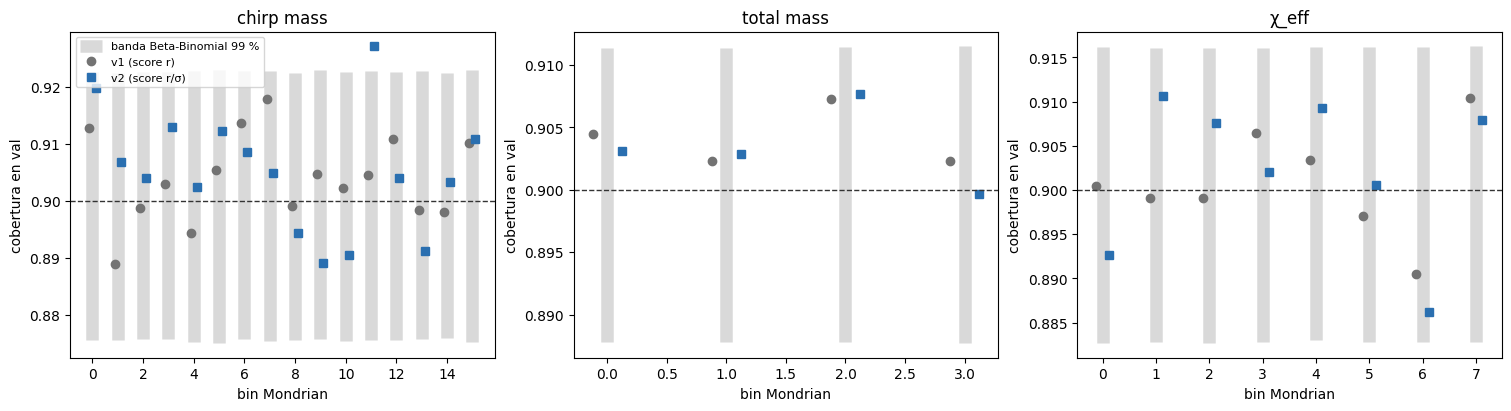

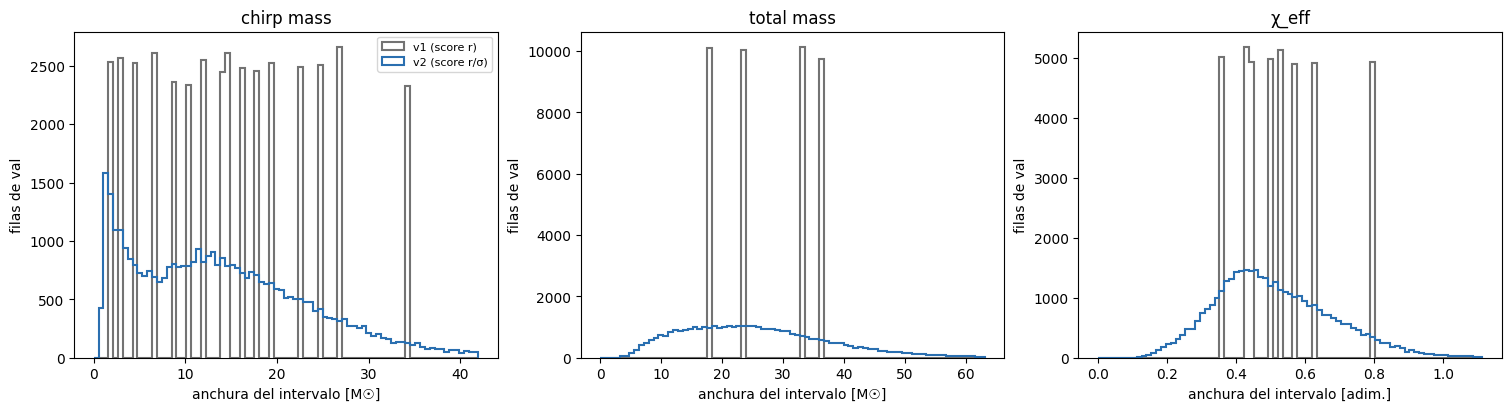

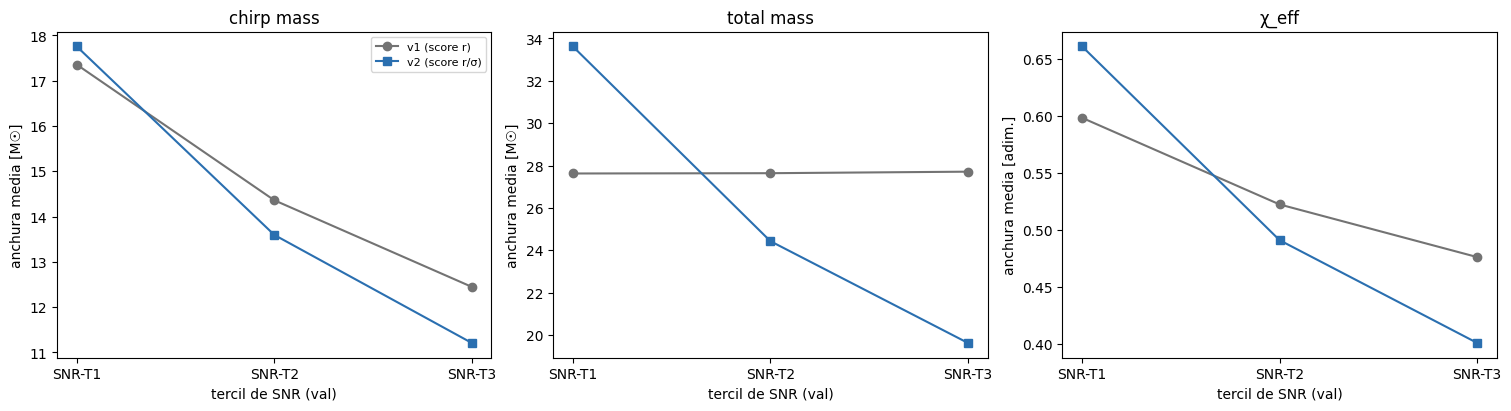

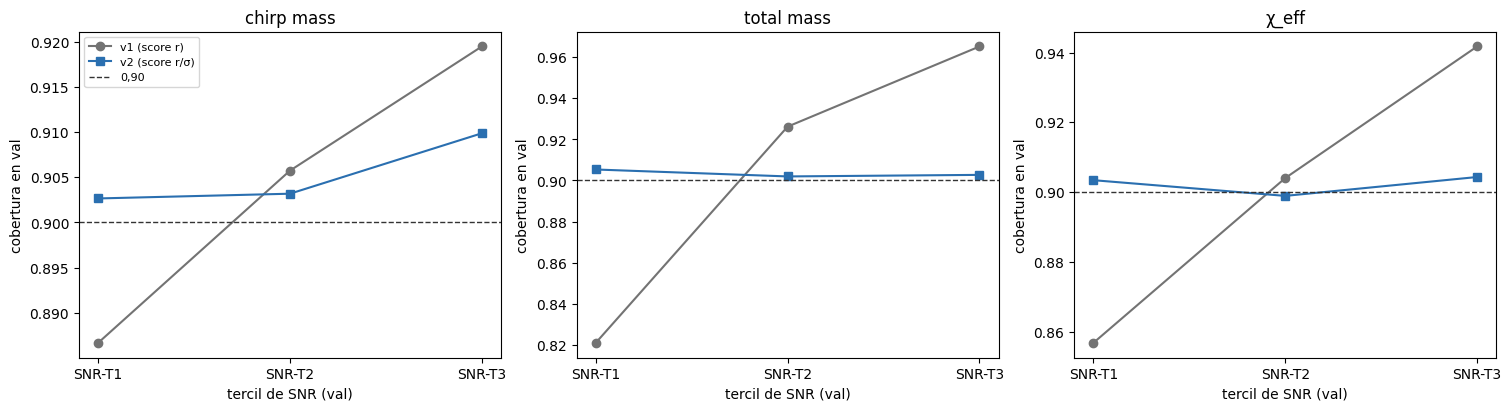

/data/vserrano/cbc_pe_data/results/M13_3/M14_3/figures/M14_3_val_coverage_per_bin_20261111T152944Z.png
/data/vserrano/cbc_pe_data/results/M13_3/M14_3/figures/M14_3_val_coverage_per_bin_20261111T152944Z.pdf
/data/vserrano/cbc_pe_data/results/M13_3/M14_3/figures/M14_3_val_width_distribution_20261111T152944Z.png
/data/vserrano/cbc_pe_data/results/M13_3/M14_3/figures/M14_3_val_width_distribution_20261111T152944Z.pdf
/data/vserrano/cbc_pe_data/results/M13_3/M14_3/figures/M14_3_val_width_by_snr_tercile_20261111T152944Z.png
/data/vserrano/cbc_pe_data/results/M13_3/M14_3/figures/M14_3_val_width_by_snr_tercile_20261111T152944Z.pdf
/data/vserrano/cbc_pe_data/results/M13_3/M14_3/figures/M14_3_val_coverage_by_snr_tercile_20261111T152944Z.png
/data/vserrano/cbc_pe_data/results/M13_3/M14_3/figures/M14_3_val_coverage_by_snr_tercile_20261111T152944Z.pdf


In [13]:
LNAME, UNITS, VERS = CONFIG["labels"], CONFIG["units"], CONFIG["versions"]
FIG_DIR.mkdir(parents=True, exist_ok=True)
FIGURES = []

def save_figure(fig, key):
    for ext in ("png", "pdf"):
        p = FIG_DIR / f"{CONFIG['fig_names'][key]}_{RUN_STAMP}.{ext}"
        with p.open("xb") as f:                      # never overwrites
            fig.savefig(f, format=ext, dpi=200, bbox_inches="tight")
        FIGURES.append(str(p))

# (a) Coverage per bin, v1 and v2, with the 99 % Beta-Binomial band (same band for both: same k, n and m per bin).
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, l in zip(axes, LABELS):
    b1 = BIN_VAL[(BIN_VAL.version == "v1") & (BIN_VAL.label == l)]
    b2 = BIN_VAL[(BIN_VAL.version == "v2") & (BIN_VAL.label == l)]
    ax.vlines(b1.mondrian_bin, b1.band_lo, b1.band_hi, color=CONFIG["band_color"], lw=9, label="banda Beta-Binomial 99 %")
    ax.plot(b1.mondrian_bin - 0.12, b1.coverage, "o", color=VERS["v1"]["color"], label=VERS["v1"]["name"])
    ax.plot(b2.mondrian_bin + 0.12, b2.coverage, "s", color=VERS["v2"]["color"], label=VERS["v2"]["name"])
    ax.axhline(HP["confidence_level"], color=CONFIG["nominal_color"], ls="--", lw=1)
    ax.set(title=LNAME[l], xlabel="bin Mondrian", ylabel="cobertura en val")
axes[0].legend(fontsize=8)
save_figure(fig, "a")
plt.show()

# (b) Distribution of physical widths, v1 vs v2.
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, l in zip(axes, LABELS):
    w1, w2 = ROW_VAL["v1"][l][1], ROW_VAL["v2"][l][1]
    edges = np.linspace(0, np.quantile(np.concatenate([w1, w2]), 0.995), 80)
    for v, w in (("v1", w1), ("v2", w2)):
        ax.hist(w, bins=edges, histtype="step", lw=1.5, color=VERS[v]["color"], label=VERS[v]["name"])
    ax.set(title=LNAME[l], xlabel=f"anchura del intervalo [{UNITS[l]}]", ylabel="filas de val")
axes[0].legend(fontsize=8)
save_figure(fig, "b")
plt.show()

# (c) Mean width per SNR tercile; (d) coverage per SNR tercile with the 0.90 line.
for key, col, ylab in (("c", "mean_width_phys", "anchura media"), ("d", "coverage", "cobertura en val")):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
    for ax, l in zip(axes, LABELS):
        for v, mk in (("v1", "o-"), ("v2", "s-")):
            t = SNR_TABLE[(SNR_TABLE.version == v) & (SNR_TABLE.label == l)]
            ax.plot(t.group, t[col], mk, color=VERS[v]["color"], label=VERS[v]["name"])
        if key == "d":
            ax.axhline(HP["confidence_level"], color=CONFIG["nominal_color"], ls="--", lw=1, label="0,90")
        ax.set(title=LNAME[l], xlabel="tercil de SNR (val)",
               ylabel=f"{ylab} [{UNITS[l]}]" if key == "c" else ylab)
    axes[0].legend(fontsize=8)
    save_figure(fig, key)
    plt.show()
print("\n".join(FIGURES))

## 12. Confirmación (test)

Una sola aplicación en test de lo ya fijado en cal: v1 (celda 8 de M13.7, sin cambios, con CSV en `RUN_DIR/m13_7_cell8_test/`) y v2 con los mismos bins de v1. Se dan la cobertura y la anchura de la política elegida en val para cada etiqueta, y las de v1. **Sin ninguna decisión.**

In [14]:
cell8_test = run_m13_7_cell8("test", SPLITS["test"], calibrators)
V1_TEST = {l: cell8_test[(PRIMARY_POLICY, l)] for l in LABELS}
V2_TEST = {l: apply_v2(V2_SYSTEMS[l], V1_TEST[l], SPLITS["test"]) for l in LABELS}
RES_TEST = {"v1": V1_TEST, "v2": V2_TEST}
test_rows = []
for l in LABELS:
    for role, v in (("v1", "v1"), ("elegida", CHOSEN[l])):
        cov, w = per_row(RES_TEST[v][l], SPLITS["test"])
        test_rows.append(dict(label=l, role=role, version=v, n=len(w), coverage=float(cov.mean()),
                              mean_width_phys=float(w.mean()), median_width_phys=float(np.median(w))))
TEST_CONFIRMATION = pd.DataFrame(test_rows)
display(TEST_CONFIRMATION)

,final_policy,label,taxonomy_mode,interval_mode,n_bins,n_test,coverage,coverage_gap_points,marginal_pass,n_bins_assessed,n_bins_fail,min_bin_coverage_assessed,max_bin_coverage_assessed,min_bin_n,bins_pass,mean_width_phys,median_width_phys,lower_miss_rate,upper_miss_rate
0,conservative,chi_eff,difficulty,symmetric,8,30000,0.904933,0.493333,True,8,0,0.896825,0.915505,3593,True,0.530870,0.504827,0.051500,0.043567
1,conservative,chirp_mass,difficulty,asymmetric,16,30000,0.901600,0.160000,True,16,1,0.876616,0.913708,1787,False,14.730655,14.349381,0.049233,0.049167
2,conservative,total_mass,prediction,asymmetric,4,30000,0.911033,1.103333,True,4,1,0.898545,0.923098,7412,False,27.737338,33.391347,0.043333,0.045633
3,efficient,chi_eff,difficulty,symmetric,4,30000,0.904367,0.436667,True,4,0,0.901145,0.907175,7311,True,0.530698,0.474782,0.052300,0.043333
4,efficient,chirp_mass,difficulty,asymmetric,48,30000,0.901800,0.180000,True,48,15,0.869010,0.933549,549,False,14.736277,13.800291,0.050400,0.047800
5,efficient,total_mass,prediction,asymmetric,4,30000,0.911033,1.103333,True,4,1,0.898545,0.923098,7412,False,27.737338,33.391347,0.043333,0.045633


,final_policy,label,mondrian_bin,n,coverage,assessed,within_2_points,median_width_phys
0,conservative,chi_eff,0,3796,0.898314,True,True,0.358611
1,conservative,chi_eff,1,3895,0.903723,True,True,0.428088
2,conservative,chi_eff,2,3817,0.901231,True,True,0.445721
3,conservative,chi_eff,3,3780,0.906614,True,True,0.504827
4,conservative,chi_eff,4,3808,0.909664,True,True,0.533880
5,conservative,chi_eff,5,3593,0.907876,True,True,0.575117
6,conservative,chi_eff,6,3654,0.896825,True,True,0.625580
7,conservative,chi_eff,7,3657,0.915505,True,True,0.793698
8,conservative,chirp_mass,0,1890,0.906349,True,True,1.642534
9,conservative,chirp_mass,1,1892,0.910677,True,True,2.803483


CRITERION (fixed before test): |coverage - 0.90| <= 0.02; per bin only if n >= 500
  conservative chi_eff    marginal 0.9049 [PASS]  bins 8/8 within [PASS]
  conservative chirp_mass marginal 0.9016 [PASS]  bins 15/16 within [FAIL]
  conservative total_mass marginal 0.9110 [PASS]  bins 3/4 within [FAIL]
  efficient    chi_eff    marginal 0.9044 [PASS]  bins 4/4 within [PASS]
  efficient    chirp_mass marginal 0.9018 [PASS]  bins 33/48 within [FAIL]
  efficient    total_mass marginal 0.9110 [PASS]  bins 3/4 within [FAIL]


,label,role,version,n,coverage,mean_width_phys,median_width_phys
0,chirp_mass,v1,v1,30000,0.901600,14.730655,14.349381
1,chirp_mass,elegida,v1,30000,0.901600,14.730655,14.349381
2,total_mass,v1,v1,30000,0.911033,27.737338,33.391347
3,total_mass,elegida,v2,30000,0.901700,25.791026,24.205305
4,chi_eff,v1,v1,30000,0.904933,0.530870,0.504827
5,chi_eff,elegida,v1,30000,0.904933,0.530870,0.504827


## 13. Descriptivo: comparación con el Mondrian de la enmienda 6 (4a-G3T), en val y test

Se usa el bundle de la enmienda 6, ajustado solo con cal de G3T sobre 4a-G3T, y se aplica con la celda 8 de M13.7, sin cambios, a las predicciones de 4a-G3T en val y test (las mismas filas). Política conservative. Es solo descriptivo.

In [15]:
with AMEND6_BUNDLE.open("rb") as f:          # local artifact of the closed enmienda 6 run
    amend6 = pickle.load(f)
check(amend6["metadata"]["model"] == REF_TAG and amend6["metadata"]["fit_split"] == "cal", "enmienda 6 bundle: 4a-G3T, cal")
REF = {}
for s, path in REF_NPZ.items():
    with np.load(path, allow_pickle=True) as z:
        check(z["label_names"].tolist() == LABELS, f"4a-G3T {s}: label order")
        check(np.array_equal(z["y_mean"], stats_mean) and np.array_equal(z["y_std"], stats_std), f"4a-G3T {s}: scaler")
        d = dict(idx=np.asarray(z[f"idx_{s}"], dtype=np.int64), pred=np.asarray(z[f"pred_{s}"], dtype=float),
                 y=np.asarray(z[f"y_{s}"], dtype=float), emb=np.asarray(z[f"emb_{s}"], dtype=float))
    check(np.array_equal(np.sort(d["idx"]), np.sort(SPLITS[s]["idx"])), f"4a-G3T {s}: same rows as M14.1")
    order = np.argsort(d["idx"])
    pos = order[np.searchsorted(d["idx"][order], SPLITS[s]["idx"])]   # align to the M14.1 row order
    REF[s] = {k: v[pos] for k, v in d.items()}
    check(np.array_equal(REF[s]["idx"], SPLITS[s]["idx"]), f"4a-G3T {s}: aligned idx")
cmp_rows = []
for s, res in (("val", RES_VAL), ("test", RES_TEST)):
    a6 = run_m13_7_cell8(f"amend6_{s}", REF[s], amend6["calibrators"])
    for l in LABELS:
        for v, r, d in (("amend6", a6[(PRIMARY_POLICY, l)], REF[s]), ("v1", res["v1"][l], SPLITS[s]),
                        ("v2", res["v2"][l], SPLITS[s])):
            cov, w = per_row(r, d)
            cmp_rows.append(dict(split=s, label=l, version=v, coverage=float(cov.mean()),
                                 mean_width_phys=float(w.mean()), median_width_phys=float(np.median(w))))
AMEND6_COMPARISON = pd.DataFrame(cmp_rows)
display(AMEND6_COMPARISON.pivot_table(index=["split", "label"], columns="version",
                                      values=["coverage", "mean_width_phys", "median_width_phys"]))

,final_policy,label,taxonomy_mode,interval_mode,n_bins,n_test,coverage,coverage_gap_points,marginal_pass,n_bins_assessed,n_bins_fail,min_bin_coverage_assessed,max_bin_coverage_assessed,min_bin_n,bins_pass,mean_width_phys,median_width_phys,lower_miss_rate,upper_miss_rate
0,conservative,chi_eff,difficulty,symmetric,8,40000,0.902700,0.2700,True,8,0,0.896538,0.910800,4856,True,0.542002,0.538583,0.050825,0.046475
1,conservative,chirp_mass,difficulty,asymmetric,16,40000,0.903575,0.3575,True,16,0,0.885559,0.916222,2291,True,14.958102,14.631974,0.046125,0.050300
2,conservative,total_mass,prediction,asymmetric,4,40000,0.904125,0.4125,True,4,0,0.900591,0.907878,9759,True,27.556258,23.663373,0.046225,0.049650
3,efficient,chi_eff,difficulty,symmetric,4,40000,0.903050,0.3050,True,4,0,0.899434,0.905672,9856,True,0.543024,0.555902,0.050750,0.046200
4,efficient,chirp_mass,difficulty,asymmetric,48,40000,0.902850,0.2850,True,48,11,0.873388,0.943750,744,False,14.964157,14.133480,0.046900,0.050250
5,efficient,total_mass,prediction,asymmetric,4,40000,0.904125,0.4125,True,4,0,0.900591,0.907878,9759,True,27.556258,23.663373,0.046225,0.049650


,final_policy,label,mondrian_bin,n,coverage,assessed,within_2_points,median_width_phys
0,conservative,chi_eff,0,5027,0.901134,True,True,0.436458
1,conservative,chi_eff,1,4951,0.902040,True,True,0.473508
2,conservative,chi_eff,2,4856,0.898476,True,True,0.492272
3,conservative,chi_eff,3,5000,0.910800,True,True,0.526796
4,conservative,chi_eff,4,5026,0.896538,True,True,0.538583
5,conservative,chi_eff,5,5037,0.901926,True,True,0.578207
6,conservative,chi_eff,6,5103,0.908485,True,True,0.609793
7,conservative,chi_eff,7,5000,0.902000,True,True,0.677216
8,conservative,chirp_mass,0,2423,0.914569,True,True,2.519469
9,conservative,chirp_mass,1,2493,0.910550,True,True,3.630910


CRITERION (fixed before test): |coverage - 0.90| <= 0.02; per bin only if n >= 500
  conservative chi_eff    marginal 0.9027 [PASS]  bins 8/8 within [PASS]
  conservative chirp_mass marginal 0.9036 [PASS]  bins 16/16 within [PASS]
  conservative total_mass marginal 0.9041 [PASS]  bins 4/4 within [PASS]
  efficient    chi_eff    marginal 0.9031 [PASS]  bins 4/4 within [PASS]
  efficient    chirp_mass marginal 0.9029 [PASS]  bins 37/48 within [FAIL]
  efficient    total_mass marginal 0.9041 [PASS]  bins 4/4 within [PASS]


,final_policy,label,taxonomy_mode,interval_mode,n_bins,n_test,coverage,coverage_gap_points,marginal_pass,n_bins_assessed,n_bins_fail,min_bin_coverage_assessed,max_bin_coverage_assessed,min_bin_n,bins_pass,mean_width_phys,median_width_phys,lower_miss_rate,upper_miss_rate
0,conservative,chi_eff,difficulty,symmetric,8,30000,0.905067,0.506667,True,8,0,0.893878,0.912675,3660,True,0.541741,0.526796,0.050567,0.044367
1,conservative,chirp_mass,difficulty,asymmetric,16,30000,0.902767,0.276667,True,16,2,0.879467,0.924123,1785,False,14.908373,14.631974,0.050433,0.046800
2,conservative,total_mass,prediction,asymmetric,4,30000,0.907567,0.756667,True,4,0,0.900856,0.916170,7384,True,27.629117,23.663373,0.045133,0.047300
3,efficient,chi_eff,difficulty,symmetric,4,30000,0.906733,0.673333,True,4,0,0.902390,0.909115,7407,True,0.542699,0.510182,0.050100,0.043167
4,efficient,chirp_mass,difficulty,asymmetric,48,30000,0.901100,0.110000,True,48,12,0.854281,0.934505,549,False,14.916556,14.133480,0.051167,0.047733
5,efficient,total_mass,prediction,asymmetric,4,30000,0.907567,0.756667,True,4,0,0.900856,0.916170,7384,True,27.629117,23.663373,0.045133,0.047300


,final_policy,label,mondrian_bin,n,coverage,assessed,within_2_points,median_width_phys
0,conservative,chi_eff,0,3825,0.906144,True,True,0.436458
1,conservative,chi_eff,1,3733,0.900080,True,True,0.473508
2,conservative,chi_eff,2,3660,0.906284,True,True,0.492272
3,conservative,chi_eff,3,3794,0.906695,True,True,0.526796
4,conservative,chi_eff,4,3675,0.893878,True,True,0.538583
5,conservative,chi_eff,5,3732,0.909432,True,True,0.578207
6,conservative,chi_eff,6,3802,0.905050,True,True,0.609793
7,conservative,chi_eff,7,3779,0.912675,True,True,0.677216
8,conservative,chirp_mass,0,1816,0.908040,True,True,2.519469
9,conservative,chirp_mass,1,1884,0.903397,True,True,3.630910


CRITERION (fixed before test): |coverage - 0.90| <= 0.02; per bin only if n >= 500
  conservative chi_eff    marginal 0.9051 [PASS]  bins 8/8 within [PASS]
  conservative chirp_mass marginal 0.9028 [PASS]  bins 14/16 within [FAIL]
  conservative total_mass marginal 0.9076 [PASS]  bins 4/4 within [PASS]
  efficient    chi_eff    marginal 0.9067 [PASS]  bins 4/4 within [PASS]
  efficient    chirp_mass marginal 0.9011 [PASS]  bins 36/48 within [FAIL]
  efficient    total_mass marginal 0.9076 [PASS]  bins 4/4 within [PASS]


coverage                     mean_width_phys             \
version             amend6        v1        v2          amend6         v1   
split label                                                                 
test  chi_eff     0.905067  0.904933  0.904400        0.541741   0.530870   
      chirp_mass  0.902767  0.901600  0.906333       14.908373  14.730655   
      total_mass  0.907567  0.911033  0.901700       27.629117  27.737338   
val   chi_eff     0.902700  0.900825  0.902200        0.542002   0.532059   
      chirp_mass  0.903575  0.903950  0.905225       14.958102  14.720336   
      total_mass  0.904125  0.904125  0.903350       27.556258  27.657463   

                            median_width_phys                        
version                  v2            amend6         v1         v2  
split label                                                          
test  chi_eff      0.516241          0.526796   0.504827   0.489294  
      chirp_mass  14.166531         14.631974  14.349381  12.910726  
      total_mass  25.791026         23.663373  33.391347  24.205305  
val   chi_eff      0.517374          0.538583   0.504827   0.490047  
      chirp_mass  14.186068         14.631974  14.349381  12.903143  
      total_mass  25.893136         23.663373  23.530149  24.313782

## 13b. Enmienda 2: cobertura por tercil de SNR en test

**Post hoc** (enmienda 2 del doc, formada tras ver val y escrita antes de calcular esto en test). Se usa el SNR nominal de G3 (`target_network_snr`), alineado por `idx_test` con el mismo código que en val y comprobando que las filas coinciden. Los terciles usan los cortes de val, sin recalcularlos. Se reutilizan los intervalos de v1 y v2 en test ya calculados en la sección 12.
- **Hipótesis:** en las tres etiquetas, v2 tiene máx. |cob_t − 0,90| ≤ 0,015 y menor que el de v1.
- **Si se confirma:** v2 en las tres etiquetas, por validez condicional; sustituye a la elegida por anchura.
- **Si no:** se mantiene la decisión pre-registrada.

Regla de parada: esta celda es el único análisis por SNR en test.

In [16]:
# Enmienda 2 (post hoc): SNR-tercile coverage in test with the val cuts (SNR_CUTS of section 8, not recomputed)
AMEND2_SNR_CUTS_DOC = (14.954, 19.980)          # val cuts as written in the doc (3 decimals)
AMEND2_MAX_GAP = 0.015
AMEND2_PREREG_CHOICE = {"chirp_mass": "v1", "total_mass": "v2", "chi_eff": "v1"}   # pre-registered decision (doc)
require(np.allclose(SNR_CUTS, AMEND2_SNR_CUTS_DOC, rtol=0, atol=5e-4), f"val SNR cuts {SNR_CUTS} differ from the doc")
require(CHOSEN == AMEND2_PREREG_CHOICE, f"criterion-3 choice {CHOSEN} differs from the doc")

# Same SNR code as in val (section 8), plus the row-alignment assert: G3 HDF5 y at idx_test = y_test of the npz.
IDX_TEST = SPLITS["test"]["idx"]
with h5py.File(G3_H5, "r") as h:
    require(SNR_KEY in h, f"G3 HDF5 lacks {SNR_KEY}")
    check(IDX_TEST.min() >= 0 and IDX_TEST.max() < h[SNR_KEY].shape[0], "SNR test: every idx_test exists in the G3 HDF5")
    SNR_TEST = read_hdf5_dataset_preserve_order(h, SNR_KEY, IDX_TEST).astype(float)
    y_h5_test = read_hdf5_dataset_preserve_order(h, "y", IDX_TEST).astype(float)
check(np.isclose(SPLITS["test"]["y"] * y_std + y_mean, y_h5_test, rtol=Y_RTOL, atol=Y_ATOL).all(),
      "SNR test: G3 HDF5 rows aligned with idx_test (y identical)")
check(np.isfinite(SNR_TEST).all() and np.all(SNR_TEST > 0), f"{SNR_KEY} finite and positive (test)")
ter_test = np.searchsorted(SNR_CUTS, SNR_TEST, side="right")      # val cuts
SNR_GROUPS_TEST = {f"SNR-T{t + 1}": ter_test == t for t in range(3)}
check(sum(int(g.sum()) for g in SNR_GROUPS_TEST.values()) == len(IDX_TEST), "SNR terciles (val cuts) partition test")
print("val SNR cuts:", SNR_CUTS, "| test rows per tercile:", {k: int(g.sum()) for k, g in SNR_GROUPS_TEST.items()})

a2_rows = []
for v in ("v1", "v2"):
    for l in LABELS:
        cov, w = per_row(RES_TEST[v][l], SPLITS["test"])     # intervals of section 12
        for g, mask in SNR_GROUPS_TEST.items():
            a2_rows.append(dict(version=v, label=l, group=g, n=int(mask.sum()), coverage=float(cov[mask].mean()),
                                mean_width_phys=float(w[mask].mean())))
AMEND2_TABLE = pd.DataFrame(a2_rows)
display(AMEND2_TABLE.pivot_table(index=["label", "group"], columns="version", values=["coverage", "mean_width_phys"]))
AMEND2_GAP = (AMEND2_TABLE.assign(gap=lambda t: (t.coverage - HP["confidence_level"]).abs())
              .groupby(["label", "version"]).gap.max().unstack("version").reindex(LABELS))
AMEND2_GAP["v2_within_max"] = AMEND2_GAP.v2 <= AMEND2_MAX_GAP
AMEND2_GAP["v2_below_v1"] = AMEND2_GAP.v2 < AMEND2_GAP.v1
display(AMEND2_GAP)
AMEND2_CONFIRMED = bool(AMEND2_GAP.v2_within_max.all() and AMEND2_GAP.v2_below_v1.all())
AMEND2_CHOICE = {l: "v2" for l in LABELS} if AMEND2_CONFIRMED else dict(AMEND2_PREREG_CHOICE)
print(f"ENMIENDA 2 (post hoc): hipótesis {'CONFIRMADA' if AMEND2_CONFIRMED else 'NO confirmada'} en test")
for l in LABELS:
    r = AMEND2_GAP.loc[l]
    print(f"  {l:10s} máx |cob_t - 0,90|: v1 {r.v1:.4f} | v2 {r.v2:.4f} "
          f"(<= {AMEND2_MAX_GAP}: {'sí' if r.v2_within_max else 'no'}; < v1: {'sí' if r.v2_below_v1 else 'no'})")
print("Política final:", AMEND2_CHOICE,
      "(v2 por validez condicional, post hoc)" if AMEND2_CONFIRMED else "(decisión pre-registrada)")

val SNR cuts: [14.95404436 19.98007806] | test rows per tercile: {'SNR-T1': 9975, 'SNR-T2': 9972, 'SNR-T3': 10053}


coverage           mean_width_phys           
version                  v1        v2              v1         v2
label      group                                                
chi_eff    SNR-T1  0.860551  0.903659        0.597090   0.657383
           SNR-T2  0.913458  0.906438        0.520296   0.490879
           SNR-T3  0.940515  0.903113        0.475651   0.401350
chirp_mass SNR-T1  0.881003  0.903459       17.478376  17.899949
           SNR-T2  0.904432  0.904432       14.370243  13.587512
           SNR-T3  0.919228  0.911071       12.361761  11.036434
total_mass SNR-T1  0.831278  0.900652       27.793644  33.643127
           SNR-T2  0.930405  0.902627       27.775780  24.396997
           SNR-T3  0.970954  0.901820       27.643337  19.382646

version,v1,v2,v2_within_max,v2_below_v1
label,,,,
chirp_mass,0.019228,0.011071,True,True
total_mass,0.070954,0.002627,True,True
chi_eff,0.040515,0.006438,True,True


ENMIENDA 2 (post hoc): hipótesis CONFIRMADA en test
  chirp_mass máx |cob_t - 0,90|: v1 0.0192 | v2 0.0111 (<= 0.015: sí; < v1: sí)
  total_mass máx |cob_t - 0,90|: v1 0.0710 | v2 0.0026 (<= 0.015: sí; < v1: sí)
  chi_eff    máx |cob_t - 0,90|: v1 0.0405 | v2 0.0064 (<= 0.015: sí; < v1: sí)
Política final: {'chirp_mass': 'v2', 'total_mass': 'v2', 'chi_eff': 'v2'} (v2 por validez condicional, post hoc)


## 14. Resumen JSON (modo `'x'`)

In [17]:
def to_json(o):
    if isinstance(o, dict):
        return {str(k) if not isinstance(k, tuple) else "/".join(map(str, k)): to_json(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_json(v) for v in o]
    if isinstance(o, np.ndarray):
        return to_json(o.tolist())
    if isinstance(o, (np.bool_,)):
        return bool(o)
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, (float, np.floating)):
        return None if not np.isfinite(o) else float(o)
    return o

def records(df):
    return df.reset_index().to_dict("records") if df.index.name or isinstance(df.index, pd.MultiIndex) else df.to_dict("records")

def input_entry(path):
    return dict(path=str(path), sha256=file_sha256(path))

summary = dict(
    experiment="M14.3", preregistration="docs/experiments/M14_3_mondrian_v2.md (11-11-2026, enmienda 1)",
    run_stamp_utc=RUN_STAMP, run_dir=str(RUN_DIR), model_tag=TAG, checkpoint=str(CHECKPOINT),
    inputs=dict(pred={s: input_entry(p) for s, p in PRED_PATHS.items()}, trainer_val=input_entry(TRAIN_VAL_NPZ),
                split=str(SPLIT_PATH), label_stats=str(LABEL_STATS_PATH), g3_h5=str(G3_H5),
                amend6_bundle=dict(path=str(AMEND6_BUNDLE), sha256=AMEND6_BUNDLE_SHA256), amend6_run=AMEND6_RUN,
                amend6_json=str(AMEND6_JSON),
                ref_npz={s: input_entry(p) for s, p in REF_NPZ.items()}),
    npz_provenance=NPZ_PROVENANCE, reused_sources=reused_sources,
    m13_7_bundle=dict(path=str(BUNDLE_PATH), sha256=BUNDLE_SHA256,
                      note="file name and metadata.method_source are fixed text of M13.7 cell 6 (they name 4b-G3)"),
    hyperparameters=HP, primary_policy=PRIMARY_POLICY,
    systems=[dict(label=l, taxonomy_mode=V1_SYSTEMS[l].taxonomy_mode, interval_mode=V1_SYSTEMS[l].interval_mode,
                  n_bins=V1_SYSTEMS[l].n_bins,
                  v1_offsets_std=V1_SYSTEMS[l].fitted.calibrator.intervals_[V1_SYSTEMS[l].label_index],
                  v2_offsets_sigma_units=V2_SYSTEMS[l].fitted.calibrator.intervals_[V2_SYSTEMS[l].label_index])
             for l in LABELS],
    gates=dict(checks=CHECKS, val_reproduction=GATE_VAL, rmse=dict(tol_rel=RMSE_REL_TOL, rows=GATE_RMSE,
               table=records(rmse_table))),
    bands=dict(marginal_level=MARGINAL_BAND_LEVEL, mc_seed=MC_SEED, mc_replicas=MC_REPLICAS, bin_level=BIN_BAND_LEVEL,
               generator_order="(v1, v2) x LABELS"),
    criterion_1_validity=dict(marginal=records(COV_VAL), bins=records(BIN_VAL), overcoverage_v2=records(OVER_V2),
                              valid=VALID),
    criterion_2_efficiency=dict(n_boot=N_BOOT, block=BLOCK, seed=SEED_BOOT, ci_level=CI_LEVEL, margin_pct=EFF_MARGIN_PCT,
                                note="paired row bootstrap of val; excludes cal noise", table=records(DECISION)),
    criterion_3_decision=dict(chosen_policy=CHOSEN),
    secondary_snr=dict(source=f"G3 nominal {SNR_KEY} of {G3_H5.name}, aligned by idx_val", cuts=SNR_CUTS,
                       table=records(SNR_TABLE), max_gap=records(SNR_GAP)),
    descriptive_tau_pred=dict(edges_s=tau_pred_edges, table=records(Z_TAU_PRED), hypothesis_holds=HYP_TAU_PRED),
    descriptive_tau_true=dict(edges_s=tau_edges, table=records(DESC_TAU_TRUE)),
    test_confirmation=dict(note="no decision", table=records(TEST_CONFIRMATION)),
    amend6_comparison=dict(note="descriptive", table=records(AMEND6_COMPARISON)),
    figures=FIGURES,
    amendment_2=dict(note="post hoc (formed on val, written before computing it on test); doc enmienda 2",
                     snr_source=f"G3 nominal {SNR_KEY} of {G3_H5.name}, aligned by idx_test", val_cuts=SNR_CUTS,
                     max_gap_threshold=AMEND2_MAX_GAP, table=records(AMEND2_TABLE), max_gap=records(AMEND2_GAP),
                     confirmed=AMEND2_CONFIRMED, preregistered_choice=AMEND2_PREREG_CHOICE, final_choice=AMEND2_CHOICE),
)
SUMMARY_STAMP = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
SUMMARY_PATH = OUT_ROOT / f"M14_3_summary_{SUMMARY_STAMP}.json"   # new file each time this cell runs ('x' mode)
summary["summary_stamp_utc"] = SUMMARY_STAMP
OUT_ROOT.mkdir(parents=True, exist_ok=True)
with SUMMARY_PATH.open("x", encoding="utf-8") as f:
    json.dump(to_json(summary), f, indent=2, ensure_ascii=False)
print("Summary:", SUMMARY_PATH)
print("Política elegida (val, criterio 3):", CHOSEN)
print("Política final (enmienda 2):", AMEND2_CHOICE)

Summary: /data/vserrano/cbc_pe_data/results/M13_3/M14_3/M14_3_summary_20261111T153122Z.json
Política elegida (val, criterio 3): {'chirp_mass': 'v1', 'total_mass': 'v2', 'chi_eff': 'v1'}
Política final (enmienda 2): {'chirp_mass': 'v2', 'total_mass': 'v2', 'chi_eff': 'v2'}


## Lectura (11-11-2026)

**Veredicto pre-registrado:** v1 y v2 válidas en las tres etiquetas; eficiencia resuelta solo en total → **política elegida: total v2; chirp y χ_eff v1.**

### Verificado (val G3T, 40 000 filas; calibración en cal G3T, 30 000; una semilla)
- **Gates:** el entrenador leyó val del memmap fp16 → rama ≤ 1e-5; máx. |Δμ| 2,2e-6 y |Δσ| 1,6e-6 (ruta de inferencia exacta). RMSE de cal +1,0 a +1,8 % y de test −1,8 a +1,2 % frente a val. y alineadas con G3 (máx. 8e-6). 79 checks.
- **Offsets de v2 en cal:** ≈ ±1,6 σ (χ_eff 1,60–1,68; chirp y total asimétricos entre −1,87 y +1,78), cerca del ±1,645 gaussiano.
- **C1 (validez):** ninguna celda por debajo de su banda en v1 ni en v2. v2 sobrecubre en chirp marginal (0,9052; límite 0,9048) y en el bin 11 (0,927; límite 0,923); según el pre-registro, no invalida.
- **C2 (anchura media v2 frente a v1):** chirp −3,6 % [−3,9; −3,3], total −6,4 % [−6,8; −6,0], χ_eff −2,8 % [−3,0; −2,5]. Solo total supera el umbral del −5 %.
- **Secundario (cobertura por tercil de SNR, no decide):** v1 total 0,821 / 0,926 / 0,965, χ_eff 0,857 / 0,904 / 0,942, chirp 0,887 / 0,906 / 0,919. v2 entre 0,899 y 0,910 en todos los terciles. máx. |cob − 0,90|: v1 0,079 / 0,043 / 0,019 frente a v2 0,005 / 0,004 / 0,010 (total / χ_eff / chirp). Anchura de v1 en total constante con el SNR (27,6 M☉); v2 de 33,6 a 19,6 M☉.
- **Descriptivo pre-registrado (hipótesis de M14.1):** por τ30 predicha, std(z) 0,988–1,013 y |mean z| ≤ 0,033 en 9/9 celdas → se cumple.
- **Test (confirmación):** total v2 0,9017 y anchura media 25,79 (v1: 0,9110 y 27,74); chirp v1 0,9016; χ_eff v1 0,9049.
- **Frente a la enmienda 6 (4a-G3T, val):** anchura media de v1 con M14.1 −1,6 % (chirp), +0,4 % (total), −1,8 % (χ_eff); v2 en total −6,0 %.

### Interpretación
- **(Verificado en val):** v1 cumple la garantía marginal y por bin, pero su cobertura depende fuertemente del SNR. Asigna la misma anchura a señales débiles y fuertes del mismo bin: a SNR 10–15 su intervalo nominal del 90 % cubre el 82 % en total y el 86 % en χ_eff. v2 traslada la información del SNR a través de σ y deja la cobertura plana.
- **(Verificado en val):** el fallo de C2 en M14.1 venía de agrupar por la verdad: con grupos calculados desde la predicción, σ está calibrada. No cambia el veredicto de M14.1.
- **(Hipótesis):** la sobrecobertura de test en la enmienda 6 se debe a que test es algo más fácil que cal (RMSE test/cal −1,7 % en total, −2,8 % en χ_eff). v2 la elimina en total pero no en χ_eff.
- El criterio primario pre-registrado (anchura) no recogía la propiedad que más distingue a v2: la validez condicional al SNR. Se registra como limitación del diseño; la decisión pre-registrada no cambia.

### Enmienda 2: resultado (post hoc, confirmado en test)
- Test, cobertura por tercil de SNR (cortes de val): v1 total 0,831 / 0,930 / 0,971, χ_eff 0,861 / 0,913 / 0,941, chirp 0,881 / 0,904 / 0,919; v2 total 0,901 / 0,903 / 0,902, χ_eff 0,904 / 0,906 / 0,903, chirp 0,903 / 0,904 / 0,911.
- máx. |cob_t − 0,90|: v1 0,071 / 0,041 / 0,019 frente a v2 0,003 / 0,006 / 0,011 (total / χ_eff / chirp). La hipótesis se confirma en las tres etiquetas (v2 ≤ 0,015 y menor que v1).
- **Política final: v2 en las tres etiquetas**, por validez condicional al SNR (decisión post hoc, formada en val y confirmada en test; sustituye a la elegida por anchura).
- Queda una ligera sobrecobertura de v2 en chirp a SNR alto (0,911 en test, 0,910 en val), coherente con std(z) = 0,977 de M14.1 en ese tercil.
- La configuración del Mondrian (taxonomías, bins, simetría) es la heredada de M11 y no está optimizada para v2. La re-selección se hará en la fase "Mondrian final", sobre el modelo congelado.

### No se puede concluir
- La cobertura condicional al SNR en datos reales.
- La variación entre semillas.
- Que r/σ sea el mejor score (paso futuro: revisión de scores).
- Los IC de anchura no incluyen el ruido de cal.
- El SNR usado es el nominal de G3 (sobreestima algo el de G3T en masa alta).